<a href="https://colab.research.google.com/github/eliasbelme/eliasbelme.github.io/blob/main/TP_GP27_FBNV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="center">

<p style="font-size:0.95em; letter-spacing:2px; color:#52514e;">UNIVERSITÉ DE TECHNOLOGIE DE TROYES · GÉNIE INDUSTRIEL</p>

<p style="font-size:1.1em; color:#2a78d6;"><b>GP27 : Gestion de production et des stocks · Projet de TP · Automne 2026</b></p>

<hr style="width:60%; border:1px solid #2a78d6;">

<h1 style="font-size:2.1em; margin-bottom:0.2em;">Feature-Based Newsvendor (FBNV)</h1>
<h3 style="font-weight:normal; margin-top:0;">Prévoir la demande et décider du stock en une seule étape :<br>application à la location de vélos en libre-service</h3>

<hr style="width:60%; border:1px solid #2a78d6;">

<p><i>Reproduction de l'article</i><br>
<b>Jing Shi (2022)</b>, « Application of the model combining demand forecasting and inventory decision in feature based newsvendor problem »,<br>
<i>Computers & Industrial Engineering</i>, vol. 173, 108709.</p>

</div>

| | |
|---|---|
| **Binôme** | **Elias Belmeliani** et **Pierre Rayer** |
| **Chargé de TP** | M. Ahmed Khemili |
| **Module** | GP27, cycle ingénieur Génie Industriel, UTT |
| **Approche** | *Predict-to-Optimize* : la décision de stock est apprise directement à partir des données |
| **Données** | Kaggle *Bike Sharing Demand*, `train.csv` : 10 886 heures de locations (Washington D.C., 2011-2012) |
| **Outils** | Python 3, pandas, scikit-learn, matplotlib, seaborn |
| **Rendu** | Semaine du 9 décembre 2026 sur Moodle : rapport, code, base Excel, slides |

> Les données de l'article (ventes BMW à Hefei) sont confidentielles. Le chargé de TP a validé l'application de la méthode à ce jeu de données public.

---

## Le problème en une phrase

Chaque heure, un gestionnaire doit décider **combien de vélos mettre à disposition**, sans connaître la demande à l'avance :

| Situation | Conséquence | Coût par vélo |
|---|---|---|
| Il manque des vélos (demande > stock) | Client perdu : **rupture** | $b = 10$ |
| Il y a trop de vélos (stock > demande) | Vélo inutilisé : **sur-stockage** | $h = 4$ |

C'est le **problème du vendeur de journaux** (*newsvendor*).

## Ce que propose l'article

| Méthode | Principe |
|---|---|
| **Two-Step** (classique) | 1) prévoir la demande moyenne, 2) ajouter un stock de sécurité fixe |
| **One-Step FBNV** (article) | apprendre **directement** la bonne quantité à commander, en mettant les coûts $b$ et $h$ dans l'apprentissage |

L'article montre que la méthode One-Step coûte moins cher. Ce notebook vérifie ce résultat sur nos données, avec **10 méthodes de prévision** comparées, dont **6 testées dans les deux stratégies**, plus **notre contribution : LightGBM ✦**.

## Sommaire

| Étape | Contenu | Lien avec l'article |
|---|---|---|
| **1** | Chargement, contrôle qualité et exploration des données (4 graphiques) | §4.1 |
| **2** | Corrélations de Pearson, standardisation et sélection des variables par Lasso | §4.2 |
| **3** | Découpage train / test (87,5 % / 12,5 %), présentation de notre contribution LightGBM ✦, et comparaison des méthodes en validation croisée | §4.3, §5.3 |
| **4** | Réglage des modèles, modèle newsvendor, Two-Step contre One-Step FBNV, sensibilité aux coûts, bilan de LightGBM ✦ | §3.2, §5.4 |
| **5** | Tableaux 8 et 9 de l'article, importance des variables, décisions de stock, export Excel | Tableaux 8-9, Fig. 6-9 |

<div style="border-left:6px solid #6250d6; background:#f4f1fe; padding:12px 18px; border-radius:8px; margin:8px 0;">
<p style="margin:0 0 6px 0; color:#6250d6; font-weight:bold; letter-spacing:1px;">✦ NOTRE CONTRIBUTION PERSONNELLE · ajoutée le 6 novembre 2026</p>
<p style="margin:0;">À la demande du chargé de TP, nous avons ajouté une méthode absente de l'article : <b>LightGBM</b> (Microsoft, 2017), en version prévision et en version quantile <b>LGBM+FB</b>. Elle est expliquée en détail en <b>section 3.0</b>, puis intégrée à toutes les comparaisons.</p>
<p style="margin:6px 0 0 0;"><b>Repère visuel :</b> tout ce qui vient de cette contribution est marqué <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ en violet</span> : les encadrés, les lignes et colonnes des tableaux, les courbes des graphiques et les lignes de code (commentaire <code># ✦ CONTRIBUTION</code>).</p>
</div>

## Comment lire ce notebook

Chaque cellule de code est entourée de trois blocs :
* **Pourquoi ?** : ce que fait la cellule et pourquoi on en a besoin ;
* **Finding (Constats chiffrés)** : les résultats obtenus ;
* **Insights (Interprétation et lien avec l'article)** : ce que ces résultats veulent dire.

> **Temps d'exécution :** environ 25 minutes sur un ordinateur portable récent (plus sur Google Colab).

# Étape 1 : Chargement, contrôle qualité et exploration des données

## 1.0 Bibliothèques et réglages

**Pourquoi ?** On importe les outils utilisés dans tout le notebook et on fixe une graine aléatoire (`RANDOM_STATE = 42`). Ainsi, chaque exécution donne exactement les mêmes chiffres.

In [1]:
%matplotlib inline
import os, io, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet, QuantileRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             mean_pinball_loss, make_scorer)

# ✦ CONTRIBUTION : LightGBM (installé automatiquement s'il manque, par exemple hors de Colab)
try:
    import lightgbm as lgb
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"], check=True)
    import lightgbm as lgb

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Style des graphiques
BLEU, ORANGE, VERT, ROUGE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#8a8984"
VIOLET, VIOLET_CLAIR = "#6250d6", "#efebfd"          # ✦ CONTRIBUTION : couleur de notre contribution
sns.set_theme(style="whitegrid", palette=[BLEU, ORANGE, VERT, "#eda100", "#e87ba4", "#6250d6", ROUGE])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)


def sauver(fig, nom):
    # Enregistre la figure en PNG 200 dpi dans le dossier figures/ (pour le rapport)
    fig.savefig(f"figures/{nom}.png", bbox_inches="tight")


CONTRIB = "LightGBM|LGBM"                           # ✦ CONTRIBUTION : mots qui repèrent nos ajouts
STYLE_CONTRIB = f"background-color: {VIOLET_CLAIR}; color: #3b2a9e; font-weight: bold;"


def tableau(df, titre, formats=None, index=False):
    # Affiche un DataFrame sous forme de tableau propre avec un titre
    df = df.reset_index(drop=True)
    lignes = df.astype(str).apply(lambda col: col.str.contains(CONTRIB)).any(axis=1)
    colonnes = [c for c in df.columns if pd.Series([str(c)]).str.contains(CONTRIB)[0]]
    if lignes.any() or colonnes:                        # ✦ CONTRIBUTION : légende du marquage
        titre += "   ·   ✦ en violet : notre contribution (LightGBM)"
    sty = df.style.set_caption(titre).format(formats or {}, precision=2)
    sty = sty.apply(lambda r: [STYLE_CONTRIB if lignes[r.name] else "" for _ in r], axis=1)   # ✦ lignes
    if colonnes:
        sty = sty.apply(lambda c: [STYLE_CONTRIB] * len(c), subset=colonnes)                 # ✦ colonnes
    sty = sty.set_table_styles([{"selector": "caption",
                                 "props": "font-weight: bold; font-size: 1.05em; text-align: left;"}])
    display(sty if index else sty.hide(axis="index"))

## 1.1 Chargement de `train.csv` et aperçu

**Pourquoi ?** On lit le fichier et on regarde les premières et dernières lignes pour comprendre ce que contient chaque colonne. Si `train.csv` n'est pas dans le dossier, il est téléchargé depuis une copie publique du fichier Kaggle.

In [2]:
URL = "https://raw.githubusercontent.com/logicalguess/kaggle-bike-sharing-demand/master/data/train.csv"
if not os.path.exists("train.csv"):
    urllib.request.urlretrieve(URL, "train.csv")

df = pd.read_csv("train.csv", parse_dates=["datetime"])
print(f"{df.shape[0]} lignes et {df.shape[1]} colonnes")
display(df.head())
display(df.tail())

10886 lignes et 12 colonnes


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
10881,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336
10882,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241
10883,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168
10884,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129
10885,2012-12-19 23:00:00,4,0,1,1,13.12,16.665,66,8.9981,4,84,88


**Finding (Constats chiffrés)**
* Le fichier contient **10 886 lignes** (une par heure) et **12 colonnes**, du 1er janvier 2011 au 19 décembre 2012.
* La cible est `count`, le nombre de vélos loués dans l'heure. Les autres colonnes décrivent le calendrier (`season`, `holiday`, `workingday`) et la météo (`weather`, `temp`, `atemp`, `humidity`, `windspeed`).

**Insights (Interprétation et lien avec l'article)**
* Chaque ligne correspond à une décision de stock : combien de vélos prévoir pour cette heure-là. Dans l'article, chaque ligne était un mois de ventes de BMW. La logique est la même.

## 1.2 Structure du tableau : dimensions et types

**Pourquoi ?** On vérifie que chaque colonne a le bon type (date, nombre entier ou décimal). Un mauvais type, par exemple un nombre lu comme du texte, fausserait tous les calculs.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10886 non-null  datetime64[us]
 1   season      10886 non-null  int64         
 2   holiday     10886 non-null  int64         
 3   workingday  10886 non-null  int64         
 4   weather     10886 non-null  int64         
 5   temp        10886 non-null  float64       
 6   atemp       10886 non-null  float64       
 7   humidity    10886 non-null  int64         
 8   windspeed   10886 non-null  float64       
 9   casual      10886 non-null  int64         
 10  registered  10886 non-null  int64         
 11  count       10886 non-null  int64         
dtypes: datetime64[us](1), float64(3), int64(8)
memory usage: 1020.7 KB


**Finding (Constats chiffrés)**
* Les 12 colonnes ont toutes le bon type : `datetime` est une date, les codes et les comptages sont des entiers, et les mesures météo sont des décimaux.
* Chaque colonne a 10 886 valeurs non nulles.

**Insights (Interprétation et lien avec l'article)**
* Aucune conversion n'est nécessaire, et on peut passer directement au contrôle des valeurs.

## 1.3 Statistiques descriptives

**Pourquoi ?** La moyenne, l'écart-type, le minimum et le maximum de chaque variable donnent l'ordre de grandeur des données. Ils permettent aussi de repérer une valeur aberrante, par exemple une humidité négative.

In [4]:
tableau(df.describe().T.reset_index().rename(columns={"index": "Variable"}),
        "Tableau 1.3 : Statistiques descriptives des variables")

Variable,count,mean,min,25%,50%,75%,max,std
datetime,10886,2011-12-27 05:56:22.399412,2011-01-01 00:00:00,2011-07-02 07:15:00,2012-01-01 20:30:00,2012-07-01 12:45:00,2012-12-19 23:00:00,nan
season,10886.00,2.51,1.00,2.00,3.00,4.00,4.00,1.12
holiday,10886.00,0.03,0.00,0.00,0.00,0.00,1.00,0.17
workingday,10886.00,0.68,0.00,0.00,1.00,1.00,1.00,0.47
weather,10886.00,1.42,1.00,1.00,1.00,2.00,4.00,0.63
temp,10886.00,20.23,0.82,13.94,20.50,26.24,41.00,7.79
atemp,10886.00,23.66,0.76,16.66,24.24,31.06,45.45,8.47
humidity,10886.00,61.89,0.00,47.00,62.00,77.00,100.00,19.25
windspeed,10886.00,12.80,0.00,7.00,13.00,17.00,57.00,8.16
casual,10886.00,36.02,0.00,4.00,17.00,49.00,367.00,49.96


**Finding (Constats chiffrés)**
* La demande `count` a une **moyenne de 191,57** vélos par heure, un **écart-type de 181,14**, un **minimum de 1** et un **maximum de 977**.
* L'écart-type est presque aussi grand que la moyenne : la demande varie énormément d'une heure à l'autre.
* Les mesures météo restent dans des plages réalistes : température de 0,8 à 41 °C, humidité de 0 à 100 %, vent de 0 à 57 km/h.

**Insights (Interprétation et lien avec l'article)**
* Une demande aussi variable rend la décision de stock difficile : une marge de sécurité unique ne peut pas convenir à toutes les heures. C'est justement le problème que l'article veut résoudre.

## 1.4 Valeurs manquantes et doublons

**Pourquoi ?** Une case vide ou une ligne répétée faussent l'apprentissage des modèles. On compte le pourcentage de valeurs manquantes par colonne et le nombre de lignes en double.

In [5]:
qualite = pd.DataFrame({
    "Variable": df.columns,
    "Valeurs manquantes": df.isna().sum().values,
    "% manquant": (df.isna().mean() * 100).values,
})
tableau(qualite, "Tableau 1.4 : Valeurs manquantes par colonne", {"% manquant": "{:.1f} %"})
print("Lignes avec au moins une valeur manquante :", df.isna().any(axis=1).sum())
print("Lignes en double :", df.duplicated().sum())
print("Dates (heures) en double :", df["datetime"].duplicated().sum())

Variable,Valeurs manquantes,% manquant
datetime,0,0.0 %
season,0,0.0 %
holiday,0,0.0 %
workingday,0,0.0 %
weather,0,0.0 %
temp,0,0.0 %
atemp,0,0.0 %
humidity,0,0.0 %
windspeed,0,0.0 %
casual,0,0.0 %


Lignes avec au moins une valeur manquante : 0
Lignes en double : 0
Dates (heures) en double : 0


**Finding (Constats chiffrés)**
* **0,0 %** de valeurs manquantes dans chaque colonne, et 0 ligne incomplète.
* **0 ligne en double** et 0 heure présente deux fois.

**Insights (Interprétation et lien avec l'article)**
* Les données sont propres : on n'a rien à supprimer ni à compléter, donc aucun biais n'est introduit à cette étape.

## 1.5 Propreté des modalités

**Pourquoi ?** Les variables `season`, `holiday`, `workingday` et `weather` sont des **codes** (1, 2, 3...). On compte chaque modalité avec `value_counts()` pour vérifier qu'aucun code inattendu (faute de saisie) n'est présent.

In [6]:
for col in ["season", "holiday", "workingday", "weather"]:
    print(f"{col} :", df[col].value_counts().sort_index().to_dict())

season : {1: 2686, 2: 2733, 3: 2733, 4: 2734}
holiday : {0: 10575, 1: 311}
workingday : {0: 3474, 1: 7412}
weather : {1: 7192, 2: 2834, 3: 859, 4: 1}


**Finding (Constats chiffrés)**
* `season` prend les valeurs 1 à 4, `holiday` et `workingday` valent 0 ou 1, et `weather` va de 1 à 4.
* Aucun code inattendu. La modalité `weather = 4` (très mauvais temps) n'apparaît qu'**une seule fois**.

**Insights (Interprétation et lien avec l'article)**
* Les codes sont propres. La modalité 4, presque vide, est conservée telle quelle : les modèles la traiteront comme un temps « encore pire » que le code 3.

## 1.6 Fuite de données : suppression de `casual` et `registered`

**Pourquoi ?** `casual` (locations des occasionnels) et `registered` (locations des abonnés) **additionnés donnent exactement** `count`, la demande à prévoir. Ces chiffres ne sont connus qu'**après** l'heure écoulée. Les garder reviendrait à donner la réponse au modèle : c'est une **fuite de données** (*data leakage*). On le vérifie, puis on les supprime.

In [7]:
egalite = (df["casual"] + df["registered"] == df["count"]).mean() * 100
print(f"casual + registered = count sur {egalite:.1f} % des lignes")
df = df.drop(columns=["casual", "registered"])
print("Colonnes restantes :", list(df.columns))

casual + registered = count sur 100.0 % des lignes
Colonnes restantes : ['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'count']


**Finding (Constats chiffrés)**
* `casual + registered = count` sur **100 % des lignes**.
* Après suppression, il reste 10 colonnes : la date, 8 variables explicatives brutes et la cible.

**Insights (Interprétation et lien avec l'article)**
* Si on gardait ces deux colonnes, n'importe quel modèle prévoirait parfaitement la demande sur nos données, mais serait inutilisable en vrai : au moment de décider du stock, on ne connaît pas encore ces chiffres. Les supprimer garantit une évaluation honnête.

## 1.7 Extraction temporelle et renommage

**Pourquoi ?** La date brute (`2011-01-01 05:00`) n'est pas utilisable telle quelle par un modèle. On en tire quatre variables utiles : l'année (`yr`), le mois (`mnth`), l'heure (`hr`) et le jour de la semaine (`weekday`, 0 = lundi). On renomme aussi trois colonnes avec les noms standards du jeu de données : `weather` devient `weathersit`, `humidity` devient `hum` et `count` devient `cnt`.

In [8]:
df["yr"] = df["datetime"].dt.year
df["mnth"] = df["datetime"].dt.month
df["hr"] = df["datetime"].dt.hour
df["weekday"] = df["datetime"].dt.dayofweek
df = df.rename(columns={"weather": "weathersit", "humidity": "hum", "count": "cnt"})

FEATURES = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
            "weathersit", "temp", "atemp", "hum", "windspeed"]
TARGET = "cnt"
print(f"{len(FEATURES)} variables explicatives et 1 cible ({TARGET})")
display(df[["datetime"] + FEATURES + [TARGET]].head())

12 variables explicatives et 1 cible (cnt)


,datetime,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,1,2011,1,0,0,5,0,1,9.84,14.395,81,0.0,16
1,2011-01-01 01:00:00,1,2011,1,1,0,5,0,1,9.02,13.635,80,0.0,40
2,2011-01-01 02:00:00,1,2011,1,2,0,5,0,1,9.02,13.635,80,0.0,32
3,2011-01-01 03:00:00,1,2011,1,3,0,5,0,1,9.84,14.395,75,0.0,13
4,2011-01-01 04:00:00,1,2011,1,4,0,5,0,1,9.84,14.395,75,0.0,1


**Finding (Constats chiffrés)**
* On dispose maintenant de **12 variables explicatives** (dont 4 tirées de la date) et d'une cible `cnt`.

**Insights (Interprétation et lien avec l'article)**
* L'heure (`hr`) sera sans doute la variable la plus importante : la demande d'un vélo dépend avant tout du moment de la journée. L'article utilise de la même façon des variables de calendrier et des variables externes pour prévoir la demande.

## 1.8 Visualisation 1 : distribution de la demande

**Pourquoi ?** On regarde comment se répartit la demande horaire. Si elle est très asymétrique, une prévision « moyenne » + une marge identique pour toutes les heures (méthode Two-Step) risque d'être mal adaptée.

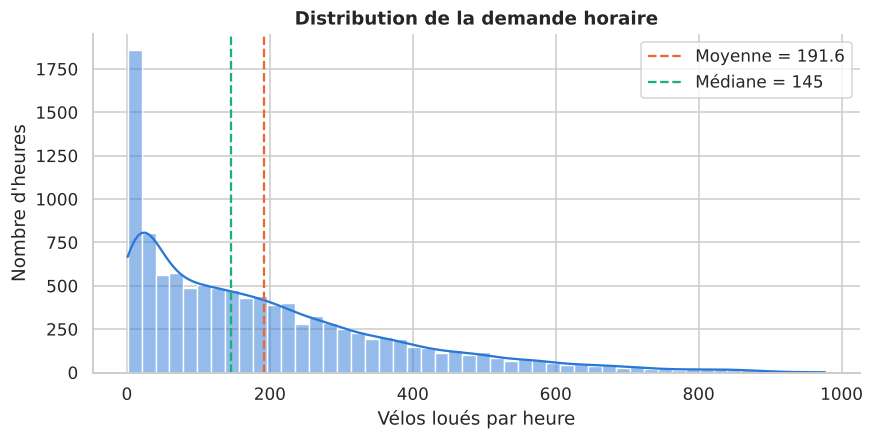

Coefficient d'asymétrie (skewness) : 1.24


In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df[TARGET], bins=50, kde=True, color=BLEU, ax=ax)
ax.axvline(df[TARGET].mean(), color=ORANGE, ls="--", label=f"Moyenne = {df[TARGET].mean():.1f}")
ax.axvline(df[TARGET].median(), color=VERT, ls="--", label=f"Médiane = {df[TARGET].median():.0f}")
ax.set(title="Distribution de la demande horaire", xlabel="Vélos loués par heure", ylabel="Nombre d'heures")
ax.legend()
sauver(fig, "fig1_distribution_demande")
plt.show()
print(f"Coefficient d'asymétrie (skewness) : {df[TARGET].skew():.2f}")

**Finding (Constats chiffrés)**
* La distribution est **asymétrique** (coefficient d'asymétrie de 1,24) : beaucoup d'heures à faible demande, et quelques heures à très forte demande.
* La moyenne (191,6) est nettement au-dessus de la médiane (145).

**Insights (Interprétation et lien avec l'article)**
* La demande ne suit pas une loi normale (une « courbe en cloche »). Or la méthode Two-Step suppose des erreurs normales pour calculer sa marge. C'est une première raison de penser que la méthode FBNV, qui ne fait pas cette hypothèse, peut faire mieux.

## 1.9 Visualisation 2 : demande par saison et valeurs extrêmes

**Pourquoi ?** Une boîte à moustaches résume la demande pour chaque saison : la boîte contient 50 % des heures, et les points au-dessus sont des heures exceptionnelles (*outliers*).

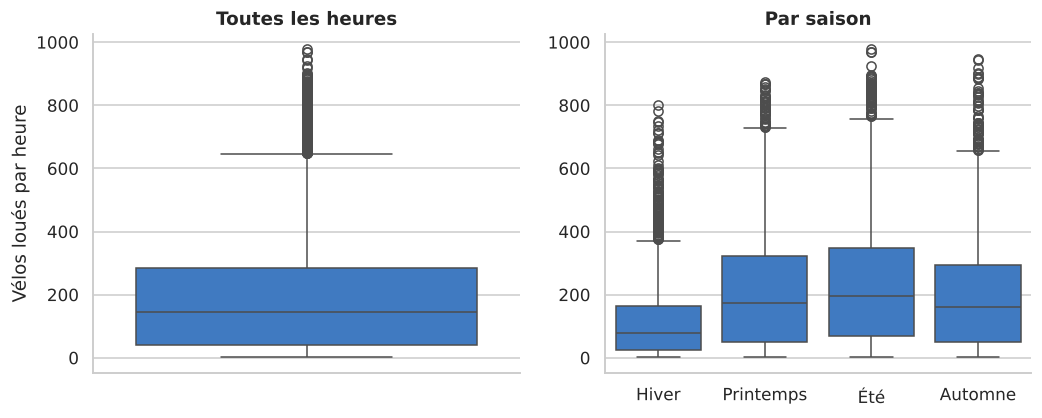

Heures au-dessus de Q3 + 1,5 x IQR : 300
season
1     78.0
2    172.0
3    195.0
4    161.0
Name: Médiane par saison, dtype: float64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(y=df[TARGET], color=BLEU, ax=axes[0])
axes[0].set(title="Toutes les heures", ylabel="Vélos loués par heure")
sns.boxplot(x="season", y=TARGET, data=df, color=BLEU, ax=axes[1])
axes[1].set_xticklabels(["Hiver", "Printemps", "Été", "Automne"])
axes[1].set(title="Par saison", xlabel="", ylabel="")
sauver(fig, "fig2_boxplots_saison")
plt.show()

q1, q3 = df[TARGET].quantile([0.25, 0.75])
print(f"Heures au-dessus de Q3 + 1,5 x IQR : {(df[TARGET] > q3 + 1.5 * (q3 - q1)).sum()}")
print(df.groupby("season")[TARGET].median().rename("Médiane par saison"))

**Finding (Constats chiffrés)**
* **300 heures** dépassent le seuil des valeurs extrêmes (Q3 + 1,5 × IQR). Ce sont surtout des heures de pointe, pas des erreurs.
* La demande médiane passe de **78 vélos en hiver** à **195 en été**.

**Insights (Interprétation et lien avec l'article)**
* On garde ces valeurs extrêmes : ce sont de vraies heures de forte demande, celles où une rupture de stock coûte le plus cher. Les supprimer reviendrait à cacher le problème au modèle.

## 1.10 Visualisation 3 : profil horaire, jours ouvrés contre week-end

**Pourquoi ?** On trace la demande moyenne pour chaque heure, séparément pour les jours ouvrés et les autres jours. Cela montre si les vélos servent surtout aux trajets domicile-travail.

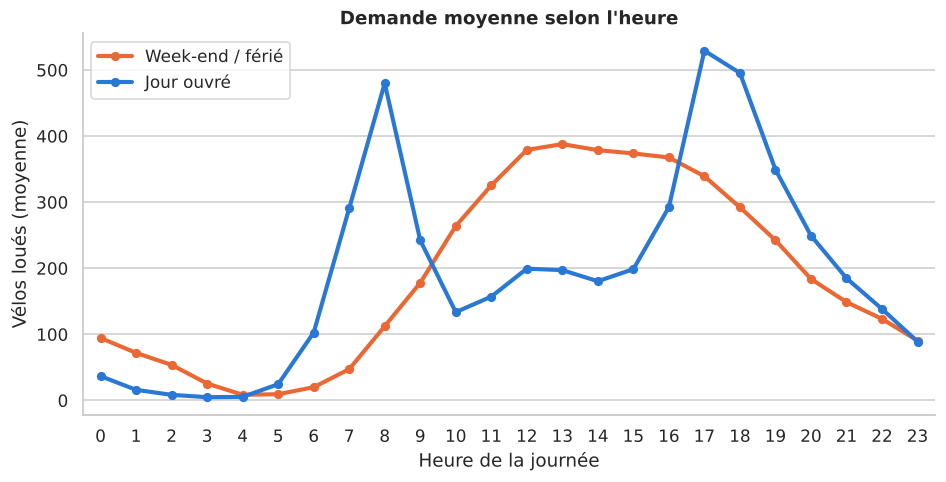

Pointe du matin (jour ouvré) : 8 h ; pointe du soir : 17 h
Heure de pointe le week-end : 13


In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.pointplot(x="hr", y=TARGET, hue="workingday", data=df, errorbar=None,
              palette=[ORANGE, BLEU], markersize=4, ax=ax)
ax.set(title="Demande moyenne selon l'heure", xlabel="Heure de la journée", ylabel="Vélos loués (moyenne)")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Week-end / férié", "Jour ouvré"])
sauver(fig, "fig3_profil_horaire")
plt.show()

profil = df.groupby(["workingday", "hr"])[TARGET].mean().unstack(0)
print("Pointe du matin (jour ouvré) :", profil[1].loc[:11].idxmax(), "h ; pointe du soir :", profil[1].loc[12:].idxmax(), "h")
print("Heure de pointe le week-end :", profil[0].idxmax())

**Finding (Constats chiffrés)**
* En jour ouvré, la courbe a **deux pics, à 8 h et à 17 h** (environ 480 et 530 vélos en moyenne), ce qui correspond aux trajets domicile-travail.
* Le week-end, la courbe est **en cloche**, avec un maximum vers **13 h** (environ 390 vélos).

**Insights (Interprétation et lien avec l'article)**
* Le besoin en vélos change complètement selon l'heure et le type de jour. Une marge de sécurité fixe sera trop grande la nuit et trop petite aux heures de pointe.

## 1.11 Visualisation 4 : effet de la température

**Pourquoi ?** Le nuage de points avec une droite de tendance (`regplot`) montre si la demande augmente avec la température.

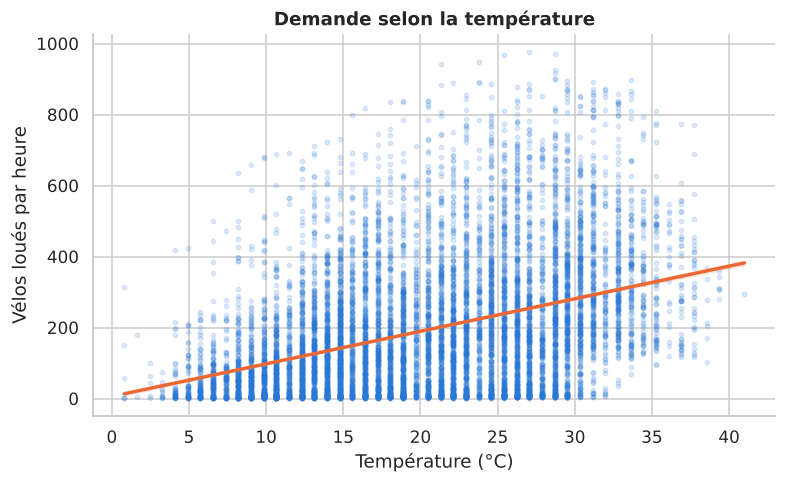

Corrélation temp / cnt : r = 0.39


In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(x="temp", y=TARGET, data=df, scatter_kws={"alpha": 0.15, "s": 8, "color": BLEU},
            line_kws={"color": ORANGE}, ax=ax)
ax.set(title="Demande selon la température", xlabel="Température (°C)", ylabel="Vélos loués par heure")
sauver(fig, "fig4_temperature")
plt.show()
print(f"Corrélation temp / cnt : r = {df['temp'].corr(df[TARGET]):.2f}")

**Finding (Constats chiffrés)**
* La demande augmente avec la température : corrélation **r = 0,39**.
* Le nuage est très dispersé : à température égale, la demande peut aller de presque 0 à plus de 800 vélos.

**Insights (Interprétation et lien avec l'article)**
* La météo compte, mais elle n'explique qu'une partie de la demande. Il faut combiner plusieurs variables (heure, météo, calendrier), ce que feront les modèles.

# Étape 2 : Corrélations, standardisation et sélection Lasso

## 2.1 Découpage train / test (87,5 % / 12,5 %)

**Pourquoi ?** On garde de côté 12,5 % des données (le **test**) pour mesurer à la fin la qualité des modèles sur des heures qu'ils n'ont jamais vues. C'est le ratio de l'article. Le découpage est fait **dès maintenant** : tout ce qui est « appris » (moyennes de standardisation, coefficients du Lasso) doit l'être sur le **train seul**, sinon le test influence nos choix et les résultats sont trop optimistes.

In [13]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.125, random_state=RANDOM_STATE)
print(f"Train : {len(X_train)} heures ({len(X_train) / len(X):.1%})")
print(f"Test  : {len(X_test)} heures ({len(X_test) / len(X):.1%})")

Train : 9525 heures (87.5%)
Test  : 1361 heures (12.5%)


**Finding (Constats chiffrés)**
* **9 525 heures (87,5 %)** pour l'entraînement et **1 361 heures (12,5 %)** pour le test, avec `random_state = 42`.

**Insights (Interprétation et lien avec l'article)**
* Le test sert d'« examen final » : aucun modèle ne le voit avant l'Étape 4. On utilise le même ratio que l'article pour que les résultats soient comparables.

## 2.2 Matrice de corrélation de Pearson

**Pourquoi ?** Le coefficient de Pearson $r$ (entre -1 et 1) mesure à quel point deux variables évoluent ensemble. On cherche deux choses : les variables liées à la demande, et les paires de variables **presque identiques** (colinéaires), qui apportent la même information deux fois.

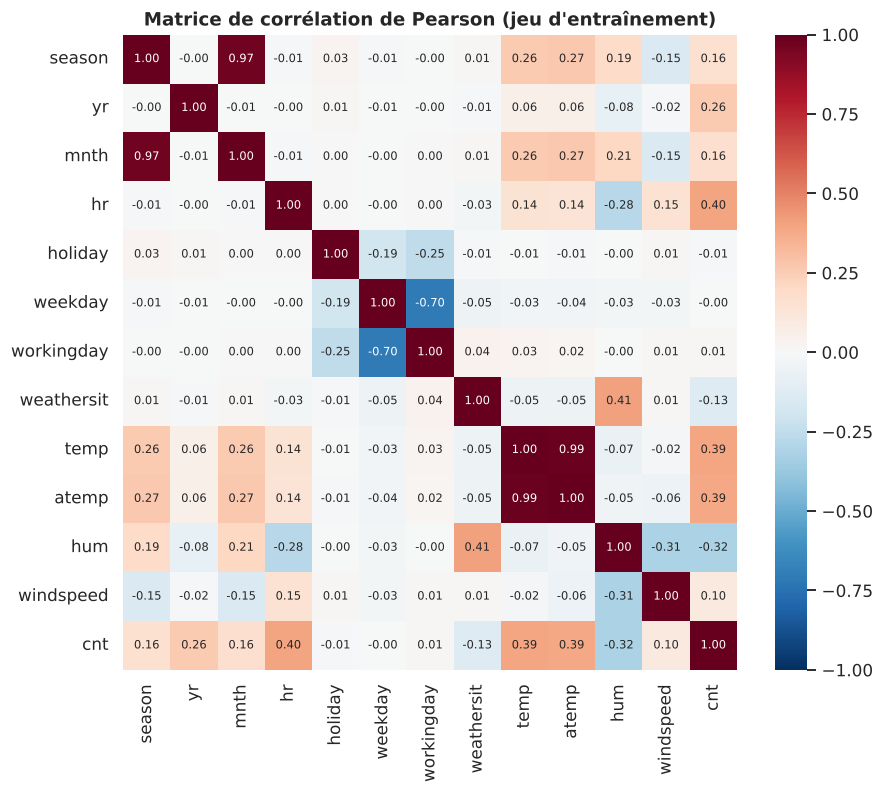

Paire,r
season / mnth,0.97
temp / atemp,0.99
weekday / workingday,-0.70


Corrélation de chaque variable avec cnt :
hr            0.40
temp          0.39
atemp         0.39
hum          -0.32
yr            0.26
mnth          0.16
season        0.16
weathersit   -0.13
windspeed     0.10
workingday    0.01
holiday      -0.01
weekday      -0.00


In [14]:
corr = pd.concat([X_train, y_train], axis=1).corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 7.5}, ax=ax)
ax.set_title("Matrice de corrélation de Pearson (jeu d'entraînement)")
sauver(fig, "fig5_correlations")
plt.show()

paires = pd.DataFrame({"Paire": ["season / mnth", "temp / atemp", "weekday / workingday"],
                       "r": [corr.loc["season", "mnth"], corr.loc["temp", "atemp"],
                             corr.loc["weekday", "workingday"]]})
tableau(paires, "Tableau 2.2 : Paires de variables fortement corrélées")
print("Corrélation de chaque variable avec cnt :")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(2).to_string())

**Finding (Constats chiffrés)**
* Trois paires sont presque redondantes : **`season` / `mnth` (r = 0,97)**, **`temp` / `atemp` (r = 0,99)** et **`weekday` / `workingday` (r = -0,70)**.
* Les variables les plus liées à la demande sont `hr` (0,40), `temp` et `atemp` (0,39), puis `hum` (-0,32).

**Insights (Interprétation et lien avec l'article)**
* Deux variables presque identiques apportent la même information deux fois. Cela rend les coefficients d'une régression instables. Le Lasso (2.4) va trancher automatiquement entre elles.

## 2.3 Standardisation

**Pourquoi ?** Les variables n'ont pas la même échelle (l'heure va de 0 à 23, l'humidité de 0 à 100). Le Lasso pénalise la taille des coefficients : sans mise à la même échelle, il favoriserait injustement certaines variables. La standardisation transforme chaque variable pour qu'elle ait une **moyenne de 0 et un écart-type de 1** :
$$x' = \frac{x - \text{moyenne}_{\text{train}}}{\text{écart-type}_{\text{train}}}$$
La moyenne et l'écart-type sont calculés **sur le train uniquement**, puis appliqués tels quels au test.

In [15]:
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)

verif = pd.DataFrame({"Variable": FEATURES, "Moyenne train": X_train_s.mean().values,
                      "Écart-type train": X_train_s.std().values, "Moyenne test": X_test_s.mean().values})
tableau(verif, "Tableau 2.3 : Contrôle de la standardisation", {c: "{:.3f}" for c in verif.columns[1:]})

Variable,Moyenne train,Écart-type train,Moyenne test
season,-0.000,1.000,0.014
yr,-0.000,1.000,0.012
mnth,0.000,1.000,0.017
hr,0.000,1.000,-0.034
holiday,-0.000,1.000,-0.019
weekday,0.000,1.000,-0.000
workingday,-0.000,1.000,0.002
weathersit,-0.000,1.000,0.003
temp,-0.000,1.000,-0.013
atemp,-0.000,1.000,-0.013


**Finding (Constats chiffrés)**
* Sur le train, chaque variable a maintenant une moyenne de 0,000 et un écart-type de 1,000.
* Sur le test, les moyennes restent proches de 0 (entre -0,034 et 0,030) sans valoir exactement 0.

**Insights (Interprétation et lien avec l'article)**
* C'est le comportement attendu : le test est transformé avec les réglages du train, comme le seraient de nouvelles données en production. On n'a donc rien appris du test.

## 2.4 Sélection des variables par Lasso (section 4.2 de l'article)

**Pourquoi ?** L'article choisit ses variables avec un **Lasso** : une régression linéaire qui ajoute une pénalité sur la somme des valeurs absolues des coefficients,
$$\min_{\beta}\ \frac{1}{2n}\sum_{i=1}^{n}(y_i - x_i^\top\beta)^2 + \alpha\sum_{j}|\beta_j|$$
Cette pénalité pousse les coefficients des variables **inutiles ou redondantes exactement à 0**. On garde les variables dont le coefficient n'est pas nul. On utilise $\alpha = 0{,}5$.

Variable,Coefficient,Décision
hr,+53.5049,Retenue
atemp,+44.5888,Retenue
yr,+40.6641,Retenue
hum,-38.9450,Retenue
mnth,+25.1309,Retenue
temp,+7.3427,Retenue
windspeed,+4.6543,Retenue
weathersit,-3.0661,Retenue
holiday,-1.1518,Retenue
weekday,+0.2568,Retenue


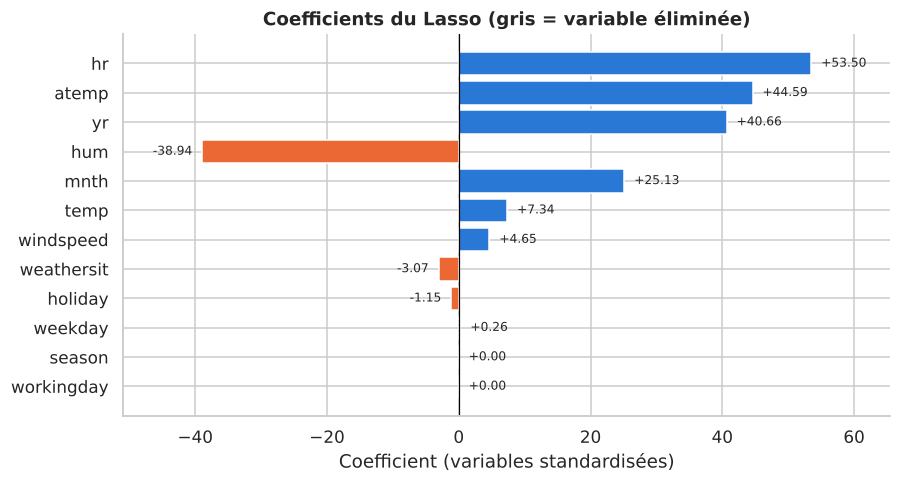

10 variables retenues : ['hr', 'atemp', 'yr', 'hum', 'mnth', 'temp', 'windspeed', 'weathersit', 'holiday', 'weekday']
Variables éliminées : ['season', 'workingday']


In [16]:
lasso = Lasso(alpha=0.5, random_state=RANDOM_STATE, max_iter=10_000).fit(X_train_s, y_train)
coefs = pd.DataFrame({"Variable": FEATURES, "Coefficient": lasso.coef_})
coefs["Décision"] = np.where(coefs["Coefficient"] != 0, "Retenue", "Éliminée")
coefs = coefs.reindex(coefs["Coefficient"].abs().sort_values(ascending=False).index)
tableau(coefs, "Tableau 2.4 : Coefficients du Lasso (alpha = 0,5)", {"Coefficient": "{:+.4f}"})

fig, ax = plt.subplots(figsize=(9, 4.5))
couleurs = [GRIS if c == 0 else (BLEU if c > 0 else ORANGE) for c in coefs["Coefficient"]]
ax.barh(coefs["Variable"], coefs["Coefficient"], color=couleurs)
for i, c in enumerate(coefs["Coefficient"]):
    ax.text(c + (1.5 if c >= 0 else -1.5), i, f"{c:+.2f}", va="center", ha="left" if c >= 0 else "right", fontsize=8)
ax.invert_yaxis()
ax.set_xlim(coefs["Coefficient"].min() - 12, coefs["Coefficient"].max() + 12)
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Coefficients du Lasso (gris = variable éliminée)", xlabel="Coefficient (variables standardisées)")
sauver(fig, "fig6_lasso")
plt.show()

VARIABLES = coefs.loc[coefs["Décision"] == "Retenue", "Variable"].tolist()
print(f"{len(VARIABLES)} variables retenues :", VARIABLES)
print("Variables éliminées :", coefs.loc[coefs["Décision"] == "Éliminée", "Variable"].tolist())

**Finding (Constats chiffrés)**
* Le Lasso met **exactement à 0** les coefficients de **`season`** et de **`workingday`**.
* Il garde **10 variables sur 12** : `hr`, `atemp`, `yr`, `hum`, `mnth`, `temp`, `windspeed`, `weathersit`, `holiday` et `weekday`.
* L'heure a le plus gros coefficient (+53,5), et l'humidité fait baisser la demande (-38,9).

**Insights (Interprétation et lien avec l'article)**
* Ce sont précisément les variables redondantes repérées en 2.2 : `season` répète `mnth`, et `workingday` se déduit de `weekday` et `holiday`. Le Lasso fait donc le même tri que l'article (section 4.2). Ces 10 variables sont utilisées dans toute la suite.

# Étape 3 : Comparaison de 10 méthodes de prévision en validation croisée

<div style="border-left:6px solid #6250d6; background:#f4f1fe; padding:12px 18px; border-radius:8px; margin:8px 0;">
<h2 style="color:#6250d6; margin-top:4px;">3.0 ✦ Notre contribution : ajouter LightGBM</h2>

<p><b>Pourquoi ?</b> Le chargé de TP nous a demandé quelle contribution nous pouvions apporter à l'article. L'article s'arrête à la Random Forest (2001), et notre meilleur modèle jusqu'ici est le Gradient Boosting. Nous avons donc cherché une méthode <b>plus récente et plus performante</b>, qui puisse aussi s'utiliser dans la logique One-Step FBNV. Nous avons choisi <b>LightGBM</b> (Microsoft, 2017), l'une des méthodes les plus utilisées dans l'industrie et dans les compétitions Kaggle sur des données en tableau.</p>

<p><b>Comment fonctionne le boosting (rappel).</b> Le modèle construit des arbres de décision les uns après les autres. Chaque nouvel arbre apprend à corriger les erreurs de la somme des arbres précédents. La prévision finale est la somme de centaines de petites corrections.</p>

<p><b>La version quantile, c'est-à-dire LGBM+FB.</b> Avec <code>objective="quantile"</code> et <code>alpha=0.7143</code>, LightGBM apprend avec la perte Pinball, donc directement avec le coût de stock. À chaque arbre, il regarde chaque heure du train :</p>
<ul>
<li>si la commande est <b>trop basse</b> (rupture), il pousse vers le haut avec un poids <b>0,714</b> (lié à b = 10) ;</li>
<li>si elle est <b>trop haute</b> (surplus), il pousse vers le bas avec un poids <b>0,286</b> (lié à h = 4).</li>
</ul>
<p>Les poussées s'équilibrent quand la commande couvre la demande 71,4 % du temps : c'est exactement la quantité optimale du newsvendor.</p>

<p><b>Ce qui distingue LightGBM du Gradient Boosting déjà utilisé</b></p>
<table>
<tr><th></th><th>Gradient Boosting (scikit-learn)</th><th style="color:#6250d6;">✦ LightGBM</th></tr>
<tr><td><b>Année</b></td><td>2001 (Friedman)</td><td>2017 (Microsoft)</td></tr>
<tr><td><b>Recherche des coupures</b></td><td>teste toutes les valeurs de chaque variable</td><td>range chaque variable dans environ 255 tranches (<b>histogrammes</b>) : plus rapide et moins sensible au bruit</td></tr>
<tr><td><b>Croissance des arbres</b></td><td>étage par étage (tous les groupes d'un même niveau)</td><td><b>feuille par feuille</b> : découpe d'abord le groupe d'heures où l'erreur est la plus grande, par exemple les heures de pointe</td></tr>
<tr><td><b>Réglage de la finesse</b></td><td><code>max_depth</code> (profondeur)</td><td><code>num_leaves</code> (nombre de groupes par arbre)</td></tr>
<tr><td><b>Version quantile (FBNV)</b></td><td><code>loss="quantile"</code></td><td><code>objective="quantile"</code></td></tr>
</table>

<p><b>Où on le retrouve dans le notebook</b> (toujours marqué ✦ en violet) :</p>
<ul>
<li><b>3.1-3.2</b> : LightGBM ajouté à la validation croisée ;</li>
<li><b>4.1</b> : réglage de ses hyperparamètres (<code>n_estimators</code>, <code>num_leaves</code>) ;</li>
<li><b>4.3-4.4</b> : LightGBM Two-Step contre LGBM+FB, et analyse de sensibilité ;</li>
<li><b>4.5</b> : bilan détaillé de la contribution (LGBM+FB contre GB+FB) ;</li>
<li><b>5.1 à 5.6</b> : Tableaux 8 et 9, graphiques, tranches horaires et export Excel.</li>
</ul>
</div>

## 3.1 Validation croisée à 5 plis

**Pourquoi ?** Le chargé de TP demande de ne pas se limiter aux 3 modèles de l'article. On compare donc **10 méthodes de prévision**, réparties en 4 familles, plus <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ LightGBM, notre contribution</span> :

| Famille | Méthodes | Principe en une phrase |
|---|---|---|
| Linéaires | Linear Regression*, Lasso*, Ridge, ElasticNet | La demande est une somme pondérée des variables (Lasso, Ridge et ElasticNet ajoutent une pénalité sur les coefficients). |
| Voisinage | KNN (k plus proches voisins) | On prend la demande moyenne des heures passées les plus ressemblantes. |
| Noyau | SVR (Support Vector Regression) | Régression qui tolère une petite marge d'erreur et peut suivre des formes courbes. |
| Arbres | Decision Tree, Random Forest*, Gradient Boosting, HistGradientBoosting | On découpe les données par questions successives (« heure < 7 ? ») ; les forêts et le boosting combinent des centaines d'arbres. |
| **✦ Contribution** | **LightGBM** | **Boosting moderne à histogrammes et croissance feuille par feuille (section 3.0).** |

\* : méthodes utilisées dans l'article.

La **validation croisée à 5 plis** découpe le train en 5 parts. Chaque modèle est entraîné 5 fois, sur 4 parts, et testé sur la part restante. On obtient 5 scores par modèle : leur moyenne dit si le modèle est bon, leur écart-type dit s'il est stable. Le test (12,5 %) n'est pas touché.

Les indicateurs :
* **RMSE** (erreur quadratique moyenne, en vélos) : pénalise fortement les grosses erreurs. Plus bas, c'est mieux.
* **MAE** (erreur absolue moyenne, en vélos) : l'erreur « typique ». Plus bas, c'est mieux.
* **R²** : part de la variation de la demande expliquée par le modèle (1 = parfait).

Les modèles linéaires, le KNN et le SVR sont placés dans un `Pipeline` avec la standardisation, pour qu'elle soit recalculée dans chaque pli. Les arbres n'en ont pas besoin.

In [17]:
Xtr, Xte = X_train[VARIABLES], X_test[VARIABLES]
ytr, yte = y_train, y_test
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

modeles = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=0.5, random_state=RANDOM_STATE)),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "ElasticNet": make_pipeline(StandardScaler(), ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=RANDOM_STATE)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
    "SVR": make_pipeline(StandardScaler(), SVR()),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    "LightGBM": lgb.LGBMRegressor(random_state=RANDOM_STATE, verbose=-1),           # ✦ CONTRIBUTION
}

resultats_cv, rmse_plis = [], {}
for nom, modele in modeles.items():
    cv = cross_validate(modele, Xtr, ytr, cv=kf,
                        scoring=("neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"))
    rmse_plis[nom] = -cv["test_neg_root_mean_squared_error"]
    resultats_cv.append({"Modèle": nom, "RMSE moyen": rmse_plis[nom].mean(), "Écart-type RMSE": rmse_plis[nom].std(),
                         "MAE moyen": -cv["test_neg_mean_absolute_error"].mean(), "R² moyen": cv["test_r2"].mean(),
                         "Temps d'entraînement (s)": cv["fit_time"].mean()})

tab_cv = pd.DataFrame(resultats_cv).sort_values("RMSE moyen")
tableau(tab_cv, "Tableau 3.1 : Validation croisée 5 plis (moyenne des 5 plis)", {"R² moyen": "{:.3f}"})

Modèle,RMSE moyen,Écart-type RMSE,MAE moyen,R² moyen,Temps d'entraînement (s)
LightGBM,40.61,1.40,25.42,0.950,0.08
HistGradientBoosting,40.64,1.51,25.49,0.950,0.23
Random Forest,42.56,1.66,25.94,0.945,0.61
Decision Tree,60.01,2.44,35.13,0.890,0.03
Gradient Boosting,67.38,1.67,45.52,0.861,0.63
KNN,114.31,1.31,79.22,0.601,0.01
Ridge,141.89,1.77,106.52,0.386,0.00
Linear Regression,141.89,1.77,106.52,0.386,0.01
Lasso,141.90,1.75,106.47,0.386,0.01
ElasticNet,141.95,1.72,106.38,0.385,0.01


**Finding (Constats chiffrés)**
* Les méthodes à base d'arbres sont de loin les meilleures : **HistGradientBoosting** (RMSE = **40,64**, R² = **0,950**), **Random Forest** (42,56 ; 0,945), **Decision Tree** (60,01 ; 0,890) et **Gradient Boosting** (67,38 ; 0,861).
* Le **KNN** est intermédiaire (RMSE = 114,31 ; R² = 0,601).
* Les 4 modèles linéaires sont tous à **RMSE ≈ 141,9** et **R² ≈ 0,386**, et le **SVR** (réglages par défaut) fait un peu moins bien (144,98).
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> **LightGBM** arrive **en tête** : RMSE = **40,61**, R² = **0,950**, juste devant HistGradientBoosting (40,64), avec l'écart-type entre plis le plus faible (1,40) et un entraînement 8 fois plus rapide que la Random Forest (0,08 s contre 0,61 s).

**Insights (Interprétation et lien avec l'article)**
* Les arbres divisent l'erreur par plus de 3 par rapport aux modèles linéaires. La demande dépend de l'heure de façon **non linéaire** (deux pics par jour), et une droite ne peut pas représenter cette forme. On retrouve la conclusion de l'article : les arbres (Random Forest) prévoient mieux que la régression linéaire et le Lasso.
* Ridge, Lasso et ElasticNet donnent presque le même résultat que la régression linéaire : la pénalité ne sert à rien quand le modèle lui-même est trop simple.
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> Sans aucun réglage, LightGBM est déjà la méthode la plus précise des 11. C'est un premier signe que notre contribution apporte un vrai gain.

## 3.2 Dispersion des erreurs sur les 5 plis

**Pourquoi ?** Le tableau donne la moyenne. La boîte à moustaches montre les 5 valeurs de RMSE de chaque modèle : une boîte étroite signifie un modèle stable, dont la performance ne dépend pas des données tirées.

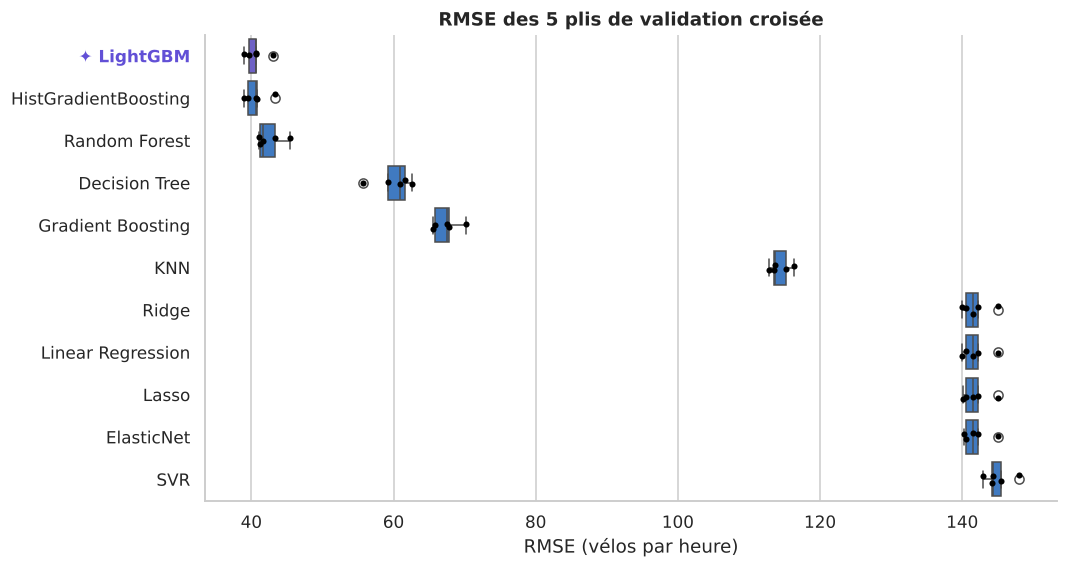

In [18]:
ordre = tab_cv["Modèle"].tolist()
plis = pd.DataFrame(rmse_plis)[ordre].melt(var_name="Modèle", value_name="RMSE")
fig, ax = plt.subplots(figsize=(10, 5.5))
couleurs_box = {m: (VIOLET if m == "LightGBM" else BLEU) for m in ordre}        # ✦ CONTRIBUTION en violet
sns.boxplot(x="RMSE", y="Modèle", data=plis, hue="Modèle", palette=couleurs_box, legend=False, ax=ax)
sns.stripplot(x="RMSE", y="Modèle", data=plis, color="black", size=4, ax=ax)
ax.set(title="RMSE des 5 plis de validation croisée", xlabel="RMSE (vélos par heure)", ylabel="")
ax.set_yticks(range(len(ordre)), [("✦ " if m == "LightGBM" else "") + m for m in ordre])   # ✦ CONTRIBUTION
for lbl in ax.get_yticklabels():
    if "LightGBM" in lbl.get_text():
        lbl.set_color(VIOLET); lbl.set_fontweight("bold")
sauver(fig, "fig7_boxplot_cv")
plt.show()

**Finding (Constats chiffrés)**
* L'écart-type entre plis ne dépasse pas 2,5 vélos, quelle que soit la méthode. Les boîtes des 4 groupes (arbres, KNN, linéaires et SVR) ne se chevauchent pas.
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> La boîte violette de LightGBM est la plus à gauche (erreur la plus faible) et l'une des plus étroites (méthode stable).

**Insights (Interprétation et lien avec l'article)**
* Le classement ne dépend pas du hasard du découpage : les méthodes à base d'arbres sont meilleures sur chacun des 5 plis.

# Étape 4 : Optimisation des stocks, Two-Step contre One-Step FBNV

## 4.1 Réglage des hyperparamètres (`GridSearchCV`)

**Pourquoi ?** Un hyperparamètre est un réglage choisi avant l'entraînement, par exemple le nombre d'arbres (`n_estimators`), leur profondeur (`max_depth`) ou le nombre de voisins (`n_neighbors`). Comme dans l'article (§5.2), on teste toutes les combinaisons d'une petite grille avec la même validation croisée à 5 plis, et on garde celle qui a le plus petit RMSE.

On règle les 4 méthodes non linéaires que l'on gardera pour la décision de stock : KNN, Decision Tree, Random Forest et Gradient Boosting, ainsi que <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ LightGBM</span> (nombre d'arbres et nombre de feuilles `num_leaves`).

In [19]:
grilles = {
    "KNN": (make_pipeline(StandardScaler(), KNeighborsRegressor()),
            {"kneighborsregressor__n_neighbors": [5, 10, 20]}),
    "Decision Tree": (DecisionTreeRegressor(random_state=RANDOM_STATE),
                      {"max_depth": [8, 12, 16], "min_samples_leaf": [5, 10, 20]}),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                      {"n_estimators": [100, 300], "max_features": [1.0, 0.6]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {"n_estimators": [300, 600], "max_depth": [4, 6]}),
    "LightGBM": (lgb.LGBMRegressor(learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1),   # ✦ CONTRIBUTION
                 {"n_estimators": [500, 1000], "num_leaves": [31, 63]}),
}
meilleurs = {}
for nom, (modele, grille) in grilles.items():
    paralleles = 1 if nom == "LightGBM" else -1          # LightGBM utilise déjà tous les cœurs lui-même
    gs = GridSearchCV(modele, grille, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=paralleles).fit(Xtr, ytr)
    meilleurs[nom] = gs

reglage = pd.DataFrame({
    "Modèle": list(grilles),
    "Meilleurs hyperparamètres": [str(gs.best_params_).replace("kneighborsregressor__", "") for gs in meilleurs.values()],
    "RMSE CV avant réglage": [tab_cv.set_index("Modèle").loc[m, "RMSE moyen"] for m in grilles],
    "RMSE CV après réglage": [-gs.best_score_ for gs in meilleurs.values()],
})
tableau(reglage, "Tableau 4.1 : Résultat de la recherche sur grille")

Modèle,Meilleurs hyperparamètres,RMSE CV avant réglage,RMSE CV après réglage
KNN,{'n_neighbors': 5},114.31,112.50
Decision Tree,"{'max_depth': 16, 'min_samples_leaf': 5}",60.01,57.57
Random Forest,"{'max_features': 1.0, 'n_estimators': 300}",42.56,42.46
Gradient Boosting,"{'max_depth': 6, 'n_estimators': 600}",67.38,38.52
LightGBM,"{'n_estimators': 1000, 'num_leaves': 63}",40.61,37.47


**Finding (Constats chiffrés)**
| Méthode | Meilleur réglage | RMSE avant | RMSE après |
|---|---|---|---|
| KNN | 5 voisins | 114,31 | 112,50 |
| Decision Tree | profondeur 16, au moins 5 heures par feuille | 60,01 | 57,57 |
| Random Forest | 300 arbres, toutes les variables | 42,56 | 42,46 |
| Gradient Boosting | 600 arbres de profondeur 6 | 67,38 | **38,52** |
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> **LightGBM** : le meilleur réglage est 1 000 arbres avec 63 feuilles, et le RMSE passe de 40,61 à **37,47**. C'est le meilleur score de validation croisée de tout le notebook.

**Insights (Interprétation et lien avec l'article)**
* Le réglage aide surtout le Gradient Boosting (-43 %) : ses réglages par défaut (arbres de profondeur 3) étaient trop simples pour suivre les pics de demande. Après réglage, il devient la meilleure des 6 méthodes gardées pour la décision de stock.
* Pour la Random Forest, le gain est faible : ses réglages par défaut étaient déjà bons.
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> Avec 63 feuilles au lieu de 31, LightGBM découpe plus finement les heures difficiles. C'est l'avantage de sa croissance feuille par feuille.

## 4.2 Le modèle du vendeur de journaux (*newsvendor*)

**Pourquoi ?** C'est le cœur de l'article : transformer une prévision en **décision de commande** $q$.

**Les coûts.** Pour une heure de demande réelle $D$ et une quantité mise à disposition $q$ :
* s'il manque des vélos ($D > q$), chaque vélo manquant coûte $b = 10$ (client perdu) ;
* s'il y a trop de vélos ($q > D$), chaque vélo en trop coûte $h = 4$ (vélo immobilisé).

$$C(q, D) = b\,(D - q)^+ + h\,(q - D)^+ \qquad \text{où } (x)^+ = \max(x, 0)$$

**La quantité optimale.** On démontre que le coût moyen est minimal quand $q$ est le **quantile d'ordre $\alpha^*$** de la demande, c'est-à-dire la quantité qui couvre la demande dans $\alpha^*$ % des cas :
$$\alpha^* = \frac{b}{b+h} = \frac{10}{14} \approx 0{,}7143$$
*Idée de la preuve :* ajouter un vélo fait gagner $b$ si la demande dépasse $q$ (probabilité $1 - F(q)$) et fait perdre $h$ sinon (probabilité $F(q)$). On s'arrête quand gain et perte s'équilibrent : $b\,(1 - F(q)) = h\,F(q)$, soit $F(q^*) = b/(b+h)$.

Comme une rupture coûte plus cher qu'un surplus, on vise **au-dessus** de la demande moyenne et on couvre environ 71 % des heures.

**Les deux stratégies comparées**

| Stratégie | Comment on calcule $q$ | Hypothèse |
|---|---|---|
| **Two-Step** (prévoir, puis optimiser) | $q_i = \hat{d}_i + z^*\,\sigma$, avec $z^* = \Phi^{-1}(\alpha^*) \approx 0{,}5659$ | Erreurs de prévision gaussiennes, avec la même incertitude $\sigma$ à toutes les heures |
| **One-Step FBNV** (méthode de l'article) | $q_i$ = prévision **directe** du quantile $\alpha^*$ | Aucune : le modèle apprend lui-même où mettre la marge |

**La perte Pinball.** Pour apprendre directement un quantile, on entraîne le modèle avec la perte Pinball (ou perte quantile) :
$$L_\alpha(y, q) = \alpha\,(y - q)^+ + (1 - \alpha)\,(q - y)^+$$
Avec $\alpha = \alpha^*$, elle vaut exactement le coût du newsvendor divisé par $b + h = 14$. **Minimiser la perte Pinball revient donc à minimiser le coût de stock.** C'est l'idée centrale du FBNV.

In [20]:
B, H = 10, 4
ALPHA = B / (B + H)
Z = norm.ppf(ALPHA)
print(f"Fractile critique alpha* = {ALPHA:.4f}")
print(f"Quantile gaussien z*      = {Z:.4f}")


def cout(y, q):
    # Coût newsvendor moyen par heure : b x manque + h x surplus
    y, q = np.asarray(y), np.asarray(q)
    return np.mean(B * np.maximum(y - q, 0) + H * np.maximum(q - y, 0))


# Vérification : perte Pinball x (b + h) = coût newsvendor
y_ex, q_ex = np.array([100, 250, 40]), np.array([120, 200, 40])
print(f"Coût newsvendor = {cout(y_ex, q_ex):.3f} ; Pinball x 14 = {mean_pinball_loss(y_ex, q_ex, alpha=ALPHA) * 14:.3f}")

Fractile critique alpha* = 0.7143
Quantile gaussien z*      = 0.5659
Coût newsvendor = 193.333 ; Pinball x 14 = 193.333


**Finding (Constats chiffrés)**
* Fractile critique **α\* = 0,7143** et quantile gaussien **z\* = 0,5659**.
* Sur un petit exemple, le coût newsvendor (193,333) est **exactement égal** à la perte Pinball × 14.

**Insights (Interprétation et lien avec l'article)**
* On vérifie numériquement l'égalité qui justifie toute la méthode FBNV : entraîner un modèle avec la perte Pinball, c'est l'entraîner directement à minimiser le coût de stock.

## 4.3 Two-Step contre One-Step FBNV sur le jeu de test

**Pourquoi ?** On applique les deux stratégies à **6 méthodes** : les 3 de l'article (LR, LA, RF) et 3 méthodes ajoutées (KNN, DT, GB), plus <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ LightGBM, notre contribution</span>. Chaque méthode a sa version One-Step, notée « +FB » comme dans l'article :

* **Two-Step** : chaque modèle prévoit la demande moyenne $\hat d_i$, puis on ajoute la marge $z^*\sigma$. L'incertitude $\sigma$ est l'écart-type des erreurs mesurées en validation croisée sur le train (et non sur les données d'entraînement elles-mêmes, où une forêt fait presque zéro erreur, ce qui donnerait une marge beaucoup trop petite).
* **One-Step FBNV (« +FB »)** : chaque modèle prévoit directement le quantile $\alpha^*$.
  * **LR+FB** : régression quantile linéaire (`QuantileRegressor`) ;
  * **LA+FB** : la même avec une pénalité Lasso ;
  * **KNN+FB** : on cherche les heures passées les plus ressemblantes et on prend le **quantile 71,43 %** de leur demande au lieu de la moyenne ;
  * **DT+FB** : l'arbre range chaque heure dans une « feuille » (un groupe d'heures semblables) ; on prend le **quantile 71,43 %** des demandes de la feuille au lieu de la moyenne ;
  * **GB+FB** : `GradientBoostingRegressor(loss="quantile", alpha=0.7143)`, réglé par `GridSearchCV` sur la perte Pinball ;
  * <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ LGBM+FB</span> : `LGBMRegressor(objective="quantile", alpha=0.7143)`, réglé par `GridSearchCV` sur la perte Pinball (nombre d'arbres et `num_leaves`) ;
  * **RF+FB** : chaque arbre de la forêt donne une prévision, et on prend le **quantile 71,43 %** de ces prévisions au lieu de leur moyenne.

Une commande ne pouvant pas être négative, on la remplace par 0 si besoin.

In [21]:
prevision = {
    "LR": make_pipeline(StandardScaler(), LinearRegression()),
    "LA": make_pipeline(StandardScaler(), Lasso(alpha=0.5, random_state=RANDOM_STATE)),
    "KNN": meilleurs["KNN"].best_estimator_,
    "DT": meilleurs["Decision Tree"].best_estimator_,
    "GB": meilleurs["Gradient Boosting"].best_estimator_,
    "RF": meilleurs["Random Forest"].best_estimator_,
    "LGBM": meilleurs["LightGBM"].best_estimator_,                                  # ✦ CONTRIBUTION
}
NOMS = {"LR": "Linear Regression", "LA": "Lasso", "KNN": "KNN", "DT": "Decision Tree",
        "GB": "Gradient Boosting", "RF": "Random Forest", "LGBM": "LightGBM"}          # ✦ CONTRIBUTION

# ---- Two-Step : prévision moyenne + marge z* x sigma ----
d_hat, sigma, q_two = {}, {}, {}
for m, modele in prevision.items():
    erreurs_cv = ytr - cross_val_predict(modele, Xtr, ytr, cv=kf)   # erreurs hors échantillon
    sigma[m] = erreurs_cv.std()
    modele.fit(Xtr, ytr)
    d_hat[m] = modele.predict(Xte)
    q_two[m] = np.maximum(d_hat[m] + Z * sigma[m], 0)

# ---- One-Step FBNV : prévision directe du quantile alpha* ----
lr_fb = make_pipeline(StandardScaler(), QuantileRegressor(quantile=ALPHA, alpha=0.0, solver="highs")).fit(Xtr, ytr)
la_fb = make_pipeline(StandardScaler(), QuantileRegressor(quantile=ALPHA, alpha=0.05, solver="highs")).fit(Xtr, ytr)

pinball = make_scorer(mean_pinball_loss, alpha=ALPHA, greater_is_better=False)
gs_gb_fb = GridSearchCV(GradientBoostingRegressor(loss="quantile", alpha=ALPHA, n_estimators=600,
                                                  learning_rate=0.05, min_samples_leaf=5, random_state=RANDOM_STATE),
                        {"max_depth": [6, 8]}, cv=kf, scoring=pinball, n_jobs=-1).fit(Xtr, ytr)

# RF+FB : prévision de chaque arbre de la forêt
preds_arbres = np.array([arbre.predict(Xte.values) for arbre in prevision["RF"].estimators_])

# KNN+FB : demandes des voisins de chaque heure de test
knn = prevision["KNN"]
voisins = knn[-1].kneighbors(knn[0].transform(Xte), return_distance=False)
demandes_voisins = ytr.values[voisins]                       # (heures de test, k voisins)

# DT+FB : demandes du train dans la feuille de chaque heure de test
arbre = prevision["DT"]
feuille_tr, feuille_te = arbre.apply(Xtr), arbre.apply(Xte)
demandes_feuille = {f: ytr.values[feuille_tr == f] for f in np.unique(feuille_tr)}


def quantile_feuilles(a):
    return np.array([np.quantile(demandes_feuille[f], a) for f in feuille_te])


q_one = {
    "LR": np.maximum(lr_fb.predict(Xte), 0),
    "LA": np.maximum(la_fb.predict(Xte), 0),
    "KNN": np.quantile(demandes_voisins, ALPHA, axis=1),
    "DT": quantile_feuilles(ALPHA),
    "GB": np.maximum(gs_gb_fb.predict(Xte), 0),
    "RF": np.quantile(preds_arbres, ALPHA, axis=0),
}
print("GB+FB, meilleur réglage :", gs_gb_fb.best_params_)

# ✦ CONTRIBUTION : LGBM+FB, LightGBM entraîné directement sur la perte Pinball (= coût de stock / 14)
gs_lgbm_fb = GridSearchCV(lgb.LGBMRegressor(objective="quantile", alpha=ALPHA, learning_rate=0.05,
                                            random_state=RANDOM_STATE, verbose=-1),
                          {"n_estimators": [1000, 2000], "num_leaves": [31, 63]},
                          cv=kf, scoring=pinball).fit(Xtr, ytr)
q_one["LGBM"] = np.maximum(gs_lgbm_fb.predict(Xte), 0)                             # ✦ CONTRIBUTION
print("✦ LGBM+FB, meilleur réglage :", gs_lgbm_fb.best_params_)

comparaison = pd.DataFrame({
    "Modèle": [NOMS[m] for m in prevision],
    "σ des erreurs (vélos)": [sigma[m] for m in prevision],
    "Coût Two-Step": [cout(yte, q_two[m]) for m in prevision],
    "Coût One-Step FBNV": [cout(yte, q_one[m]) for m in prevision],
    "Taux de service Two-Step": [np.mean(yte.values <= q_two[m]) for m in prevision],
    "Taux de service FBNV": [np.mean(yte.values <= q_one[m]) for m in prevision],
})
comparaison["Gain FBNV"] = 1 - comparaison["Coût One-Step FBNV"] / comparaison["Coût Two-Step"]
tableau(comparaison, "Tableau 4.3 : Coût moyen par heure sur le jeu de test (b = 10, h = 4)",
        {"Taux de service Two-Step": "{:.1%}", "Taux de service FBNV": "{:.1%}", "Gain FBNV": "{:+.2%}"})

GB+FB, meilleur réglage : {'max_depth': 8}


✦ LGBM+FB, meilleur réglage : {'n_estimators': 2000, 'num_leaves': 63}


Modèle,σ des erreurs (vélos),Coût Two-Step,Coût One-Step FBNV,Taux de service Two-Step,Taux de service FBNV,Gain FBNV
Linear Regression,141.91,718.04,686.23,78.7%,72.2%,+4.43%
Lasso,141.91,719.02,715.59,78.8%,71.9%,+0.48%
KNN,112.49,519.32,482.34,83.6%,68.7%,+7.12%
Decision Tree,57.64,222.28,189.22,85.1%,67.0%,+14.88%
Gradient Boosting,38.54,154.42,142.44,80.8%,67.7%,+7.76%
Random Forest,42.47,169.53,154.18,83.2%,73.3%,+9.05%
LightGBM,37.49,150.27,134.25,81.3%,64.7%,+10.66%


**Finding (Constats chiffrés)**
* Pour les **6 méthodes**, le **One-Step FBNV coûte moins cher** que le Two-Step :

| Méthode | Two-Step | One-Step FBNV | Baisse |
|---|---|---|---|
| Linear Regression | 718,04 | 686,23 | -4,43 % |
| Lasso | 719,02 | 715,59 | -0,48 % |
| KNN | 519,32 | 482,34 | -7,12 % |
| Decision Tree | 222,28 | 189,22 | **-14,88 %** |
| Gradient Boosting | 154,42 | **142,44** | -7,76 % |
| Random Forest | 169,53 | 154,18 | -9,05 % |

* Le **GB+FB** a le coût le plus bas : **142,44 par heure**. Le **Decision Tree** est la méthode où le FBNV fait le plus baisser le coût (-14,88 %).
* Les commandes Two-Step couvrent la demande 79 % à 85 % du temps, au-delà de la cible de 71,4 %. Le FBNV est plus proche de la cible (67 % à 73 %).
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> **LGBM+FB** coûte **134,25 par heure**, contre 150,27 en Two-Step (**−10,66 %**). C'est le **nouveau coût le plus bas** du notebook, devant GB+FB (142,44). Son meilleur réglage est 2 000 arbres avec 63 feuilles.

**Insights (Interprétation et lien avec l'article)**
* Le Two-Step met la même marge partout et commande donc trop en moyenne. Le FBNV place la marge là où l'incertitude est réelle. On confirme le résultat principal de l'article sur 6 méthodes différentes : intégrer les coûts dans l'apprentissage fait baisser le coût de stock.
* Le gain dépend de la qualité de la méthode : avec un modèle linéaire, qui prévoit mal, il reste faible (-0,48 % pour le Lasso).
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> Notre contribution améliore le meilleur résultat : la méthode de l'article fonctionne encore mieux avec un modèle plus précis.

## 4.4 Analyse de sensibilité au ratio $b/(b+h)$

**Pourquoi ?** Le résultat dépend-il du choix $b = 10$, $h = 4$ ? On fait varier le fractile critique $\alpha = b/(b+h)$ de 0,10 (surplus très coûteux) à 0,95 (rupture très coûteuse), en gardant $b + h = 14$. Pour chaque $\alpha$, on recalcule les deux commandes et leur coût. Le 6e graphique, sur fond violet, est celui de ✦ LightGBM.

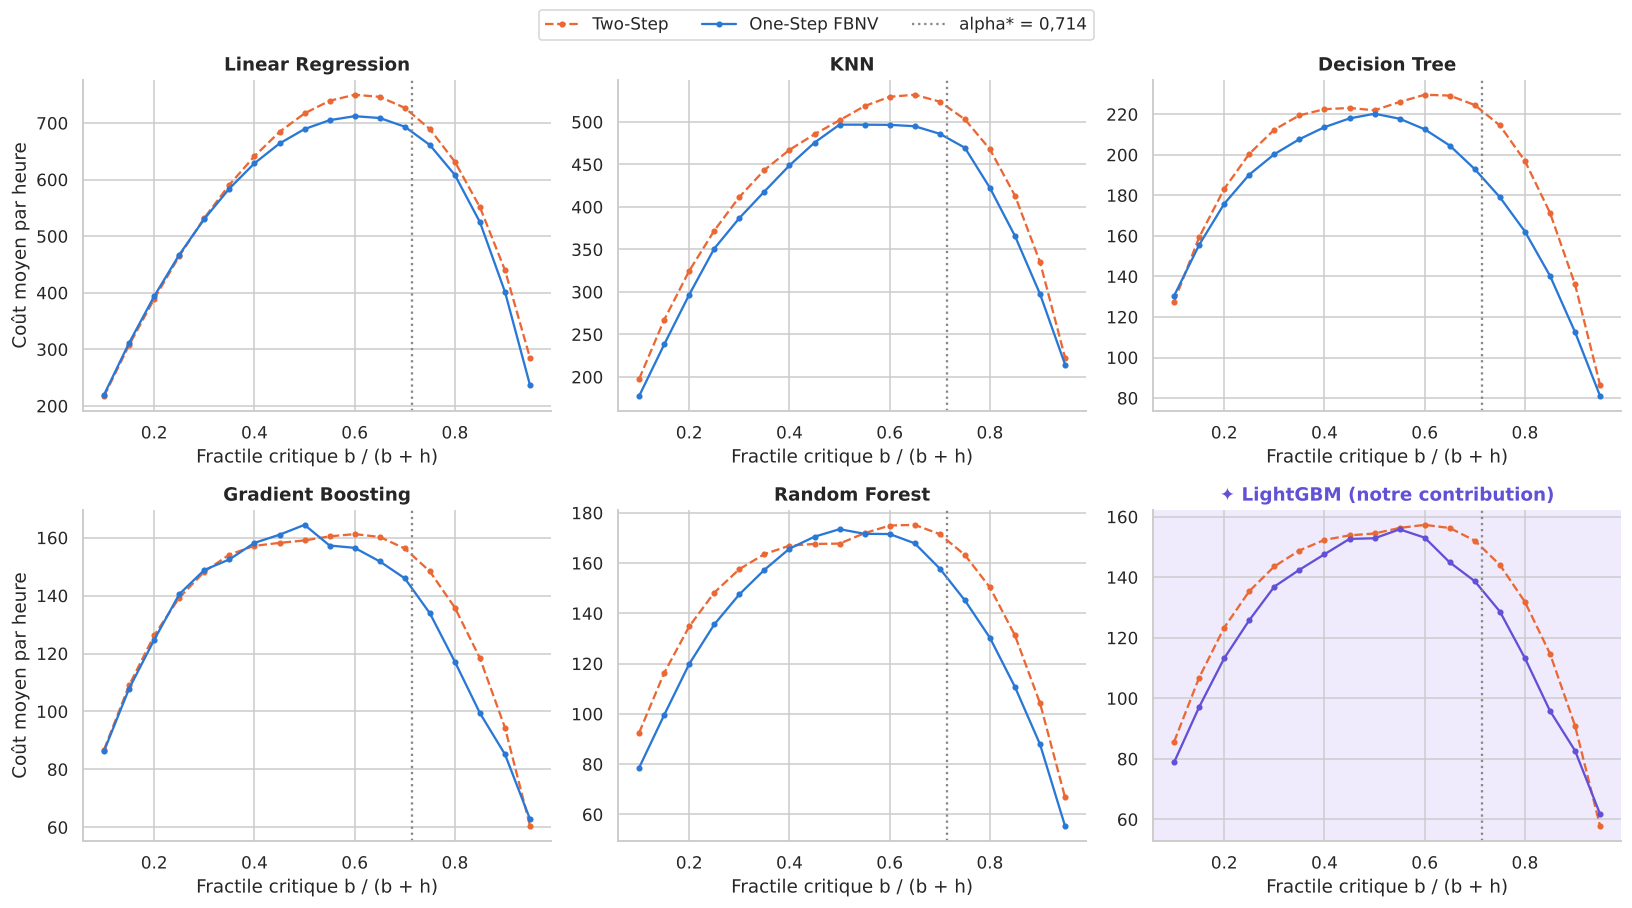

LR : FBNV moins cher pour 14 valeurs de alpha sur 18 ; alpha où il perd : [0.1, 0.15, 0.2, 0.25]
KNN : FBNV moins cher pour 18 valeurs de alpha sur 18 ; alpha où il perd : []
DT : FBNV moins cher pour 17 valeurs de alpha sur 18 ; alpha où il perd : [0.1]
GB : FBNV moins cher pour 12 valeurs de alpha sur 18 ; alpha où il perd : [0.25, 0.3, 0.4, 0.45, 0.5, 0.95]
RF : FBNV moins cher pour 16 valeurs de alpha sur 18 ; alpha où il perd : [0.45, 0.5]
LGBM : FBNV moins cher pour 17 valeurs de alpha sur 18 ; alpha où il perd : [0.95]


In [22]:
alphas = np.round(np.arange(0.10, 0.951, 0.05), 2)
lignes = []
for a in alphas:
    b_a, h_a = 14 * a, 14 * (1 - a)
    c = lambda q: np.mean(b_a * np.maximum(yte.values - q, 0) + h_a * np.maximum(q - yte.values, 0))
    z_a = norm.ppf(a)
    gb_a = clone(gs_gb_fb.best_estimator_).set_params(alpha=a).fit(Xtr, ytr)   # même GB+FB, autre quantile
    lr_a = make_pipeline(StandardScaler(), QuantileRegressor(quantile=a, alpha=0.0, solver="highs")).fit(Xtr, ytr)
    lignes.append({"alpha": a,
                   "LR Two-Step": c(np.maximum(d_hat["LR"] + z_a * sigma["LR"], 0)),
                   "LR+FB": c(np.maximum(lr_a.predict(Xte), 0)),
                   "KNN Two-Step": c(np.maximum(d_hat["KNN"] + z_a * sigma["KNN"], 0)),
                   "KNN+FB": c(np.quantile(demandes_voisins, a, axis=1)),
                   "DT Two-Step": c(np.maximum(d_hat["DT"] + z_a * sigma["DT"], 0)),
                   "DT+FB": c(quantile_feuilles(a)),
                   "GB Two-Step": c(np.maximum(d_hat["GB"] + z_a * sigma["GB"], 0)),
                   "GB+FB": c(np.maximum(gb_a.predict(Xte), 0)),
                   "RF Two-Step": c(np.maximum(d_hat["RF"] + z_a * sigma["RF"], 0)),
                   "RF+FB": c(np.quantile(preds_arbres, a, axis=0)),
                   "LGBM Two-Step": c(np.maximum(d_hat["LGBM"] + z_a * sigma["LGBM"], 0)),        # ✦ CONTRIBUTION
                   "LGBM+FB": c(np.maximum(clone(gs_lgbm_fb.best_estimator_).set_params(alpha=a)
                                           .fit(Xtr, ytr).predict(Xte), 0))})              # ✦ CONTRIBUTION
sens = pd.DataFrame(lignes)

SENS = ["LR", "KNN", "DT", "GB", "RF", "LGBM"]                                     # ✦ CONTRIBUTION : LGBM
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, m in zip(axes, SENS):
    ax.plot(sens["alpha"], sens[f"{m} Two-Step"], color=ORANGE, ls="--", marker="o", ms=3, label="Two-Step")
    ax.plot(sens["alpha"], sens[f"{m}+FB"], color=VIOLET if m == "LGBM" else BLEU, marker="o", ms=3,
            label="One-Step FBNV")
    ax.axvline(ALPHA, color=GRIS, ls=":", label="alpha* = 0,714")
    ax.set(title=NOMS[m], xlabel="Fractile critique b / (b + h)")
    if m == "LGBM":                                                                 # ✦ CONTRIBUTION
        ax.set_facecolor(VIOLET_CLAIR)
        ax.set_title("✦ LightGBM (notre contribution)", color=VIOLET)
axes[0].set_ylabel("Coût moyen par heure")
axes[3].set_ylabel("Coût moyen par heure")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, fontsize=11, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
sauver(fig, "fig8_sensibilite")
plt.show()

for m in SENS:
    gagne = (sens[f"{m}+FB"] < sens[f"{m} Two-Step"])
    print(f"{m} : FBNV moins cher pour {gagne.sum()} valeurs de alpha sur {len(alphas)} ;"
          f" alpha où il perd : {sens.loc[~gagne, 'alpha'].tolist()}")

**Finding (Constats chiffrés)**
* Nombre de valeurs de α (sur 18) où le FBNV est moins cher : **KNN 18**, **Decision Tree 17**, **Random Forest 16**, **Linear Regression 14** et **Gradient Boosting 12**.
* Entre α = 0,55 et α = 0,90, le FBNV gagne pour les 5 méthodes. Les seuls cas où il perd sont à des α faibles ou moyens (entre 0,10 et 0,50), et le GB à α = 0,95, où les deux courbes sont presque confondues. Dans ces cas, l'écart est faible.
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> **LightGBM** : le FBNV est moins cher pour **17 valeurs de α sur 18**. Il ne perd qu'à α = 0,95, où les deux courbes se touchent (graphique sur fond violet).

**Insights (Interprétation et lien avec l'article)**
* Le FBNV est d'autant plus utile que la rupture coûte cher par rapport au stockage, ce qui est le cas de notre exemple (b = 10, h = 4) et le cas courant en pratique. Le résultat ne dépend donc pas d'un choix particulier de coûts.

<div style="border-left:6px solid #6250d6; background:#f4f1fe; padding:12px 18px; border-radius:8px; margin:8px 0;">
<h2 style="color:#6250d6; margin-top:4px;">4.5 ✦ Bilan de notre contribution : LGBM+FB contre GB+FB</h2>
<p><b>Pourquoi ?</b> Avant notre contribution, la meilleure méthode était le Gradient Boosting en version quantile (GB+FB). On compare ici en détail les deux méthodes One-Step : le coût de stock, le taux de service (part des heures où la commande couvre la demande, cible : 71,4 %), le coût par tranche horaire et le temps d'entraînement. Le graphique replace LGBM+FB parmi toutes les méthodes FBNV.</p>
</div>

Méthode,Réglage retenu,Coût moyen par heure,Taux de service,Coût la nuit (0h-6h),Coût aux heures de pointe,Temps d'entraînement (s)
GB+FB,{'max_depth': 8},142.44,67.7%,46.66,234.66,18.3
LGBM+FB,"{'n_estimators': 2000, 'num_leaves': 63}",134.25,64.7%,42.52,220.56,2.4


✦ LGBM+FB coûte 5.75% de moins que GB+FB, et 13.06% de moins que le meilleur Two-Step de l'article (GB).


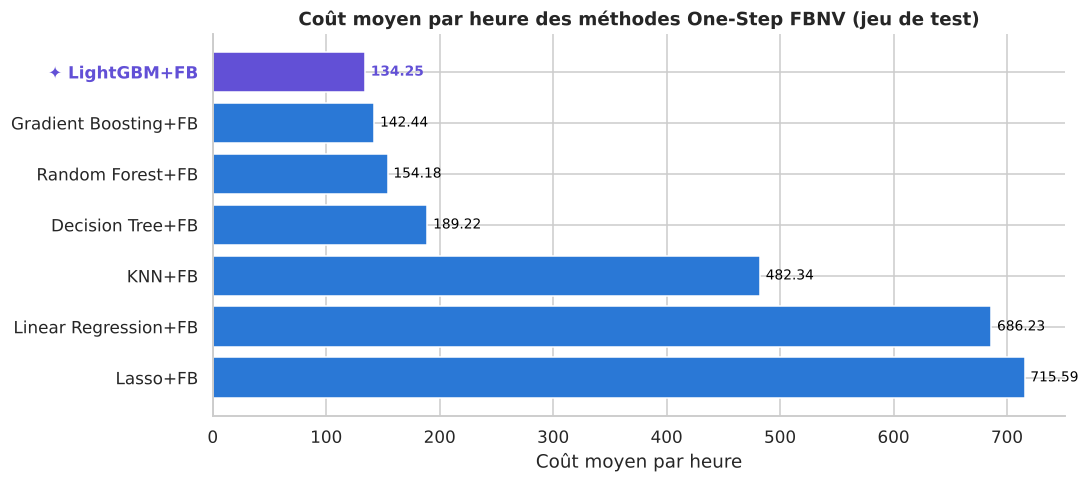

In [23]:
# ============================================================================
# ✦ CONTRIBUTION : bilan LightGBM quantile (LGBM+FB) contre Gradient Boosting quantile (GB+FB)
# ============================================================================
import time
heure_te = X_test["hr"].values
pointe = np.isin(heure_te, [7, 8, 9, 17, 18, 19])
nuit = heure_te <= 6

temps = {}
for nom, modele in [("GB+FB", gs_gb_fb.best_estimator_), ("LGBM+FB", gs_lgbm_fb.best_estimator_)]:
    t0 = time.time()
    clone(modele).fit(Xtr, ytr)
    temps[nom] = time.time() - t0

bilan = pd.DataFrame([{"Méthode": nom, "Réglage retenu": str(reg),
                       "Coût moyen par heure": cout(yte, q_one[m]),
                       "Taux de service": np.mean(yte.values <= q_one[m]),
                       "Coût la nuit (0h-6h)": cout(yte.values[nuit], q_one[m][nuit]),
                       "Coût aux heures de pointe": cout(yte.values[pointe], q_one[m][pointe]),
                       "Temps d'entraînement (s)": temps[nom]}
                      for nom, m, reg in [("GB+FB", "GB", gs_gb_fb.best_params_),
                                          ("LGBM+FB", "LGBM", gs_lgbm_fb.best_params_)]])
tableau(bilan, "Tableau 4.5 : LGBM+FB (notre contribution) contre GB+FB (meilleure méthode avant)",
        {"Taux de service": "{:.1%}", "Temps d'entraînement (s)": "{:.1f}"})
gain = 1 - cout(yte, q_one["LGBM"]) / cout(yte, q_one["GB"])
print(f"✦ LGBM+FB coûte {gain:.2%} de moins que GB+FB, "
      f"et {1 - cout(yte, q_one['LGBM']) / cout(yte, q_two['GB']):.2%} de moins que le meilleur Two-Step de l'article (GB).")

# Classement de toutes les méthodes One-Step FBNV
couts_fb = pd.Series({NOMS[m] + "+FB": cout(yte, q_one[m]) for m in prevision}).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
couleurs = [VIOLET if "LightGBM" in n else BLEU for n in couts_fb.index]
ax.barh([("✦ " if "LightGBM" in n else "") + n for n in couts_fb.index], couts_fb.values, color=couleurs)
for i, v in enumerate(couts_fb.values):
    ax.text(v + 5, i, f"{v:.2f}", va="center", fontsize=9,
            color=VIOLET if "LightGBM" in couts_fb.index[i] else "black",
            fontweight="bold" if "LightGBM" in couts_fb.index[i] else "normal")
for lbl in ax.get_yticklabels():
    if "LightGBM" in lbl.get_text():
        lbl.set_color(VIOLET); lbl.set_fontweight("bold")
ax.invert_yaxis()
ax.set(title="Coût moyen par heure des méthodes One-Step FBNV (jeu de test)", xlabel="Coût moyen par heure")
sauver(fig, "fig12_contribution_lightgbm")
plt.show()

<div style="border-left:6px solid #6250d6; background:#f4f1fe; padding:12px 18px; border-radius:8px; margin:8px 0;">

**Finding (Constats chiffrés)**

| | GB+FB (avant) | ✦ LGBM+FB (notre contribution) |
|---|---|---|
| Coût moyen par heure | 142,44 | **134,25** |
| Coût la nuit (0h-6h) | 46,66 | **42,52** |
| Coût aux heures de pointe | 234,66 | **220,56** |
| Taux de service (cible 71,4 %) | 67,7 % | 64,7 % |
| Temps d'entraînement | 18,3 s | **2,4 s** |

* LGBM+FB coûte **5,75 % de moins** que GB+FB, et **13,06 % de moins** que le Gradient Boosting Two-Step, le meilleur modèle classique.
* Il est meilleur dans toutes les tranches horaires, et il s'entraîne **7 fois plus vite**.
* Dans le classement de toutes les méthodes FBNV, LGBM+FB arrive premier (barre violette).

**Insights (Interprétation et lien avec l'article)**

* Notre contribution améliore le meilleur résultat obtenu avec les méthodes de l'article et des TP, sans changer la méthode : seul le modèle est plus performant.
* Le taux de service de LGBM+FB (64,7 %) reste sous la cible de 71,4 % : le modèle commande un peu trop peu. Pourtant, il coûte moins cher, parce que ses erreurs sont plus petites. Une calibration du quantile serait la prochaine amélioration naturelle.
* Le gain vient bien de la méthode : même réglage sur le coût (perte Pinball), mêmes données, même test. Seul l'algorithme change.

</div>

# Étape 5 : Résultats finaux (Tableaux 8 et 9) et livrables

## 5.1 Tableau 8 : qualité des prévisions sur le jeu de test

**Pourquoi ?** Le Tableau 8 de l'article compare la précision des modèles de prévision sur le test, avec 4 indicateurs : RMSE, MAE, MSE (= RMSE²) et R². On le reproduit pour nos 6 méthodes (réglées à l'Étape 4), plus ✦ LightGBM.

In [24]:
tab8 = pd.DataFrame([{"Modèle": nom, "RMSE": np.sqrt(mean_squared_error(yte, d_hat[m])),
                      "MAE": mean_absolute_error(yte, d_hat[m]), "MSE": mean_squared_error(yte, d_hat[m]),
                      "R²": r2_score(yte, d_hat[m])}
                     for m, nom in NOMS.items()])
tableau(tab8.sort_values("RMSE"), "Tableau 8 : Précision des prévisions sur le jeu de test (1 361 heures)",
        {"MSE": "{:,.0f}", "R²": "{:.3f}"})

Modèle,RMSE,MAE,MSE,R²
LightGBM,36.13,22.14,"1,305",0.960
Gradient Boosting,37.10,22.92,"1,376",0.958
Random Forest,39.97,23.96,"1,597",0.951
Decision Tree,53.92,31.71,"2,908",0.912
KNN,108.54,71.71,"11,780",0.642
Linear Regression,140.54,104.01,"19,751",0.400
Lasso,140.54,103.94,"19,751",0.400


**Finding (Constats chiffrés)**

| Méthode | RMSE | MAE | R² |
|---|---|---|---|
| Gradient Boosting | **37,10** | **22,92** | **0,958** |
| Random Forest | 39,97 | 23,96 | 0,951 |
| Decision Tree | 53,92 | 31,71 | 0,912 |
| KNN | 108,54 | 71,71 | 0,642 |
| Linear Regression | 140,54 | 104,01 | 0,400 |
| Lasso | 140,54 | 103,94 | 0,400 |

* Les scores sur le test sont très proches de ceux de la validation croisée : il n'y a pas de surapprentissage.
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> **LightGBM** prend la **1re place** du Tableau 8 : RMSE = **36,13**, MAE = 22,14, R² = **0,960**.

**Insights (Interprétation et lien avec l'article)**
* Comme dans le Tableau 8 de l'article, les modèles à base d'arbres prévoient bien mieux que les modèles linéaires. Le Gradient Boosting et la Random Forest expliquent environ 95 % des variations de la demande, contre 40 % pour les modèles linéaires.

## 5.2 Importance des variables (Random Forest)

**Pourquoi ?** L'article indique quelles variables comptent le plus pour la forêt aléatoire. L'importance **MDI** (*Mean Decrease in Impurity*) mesure de combien chaque variable réduit l'erreur, en moyenne, quand un arbre l'utilise pour couper les données. Les importances font 100 % au total.

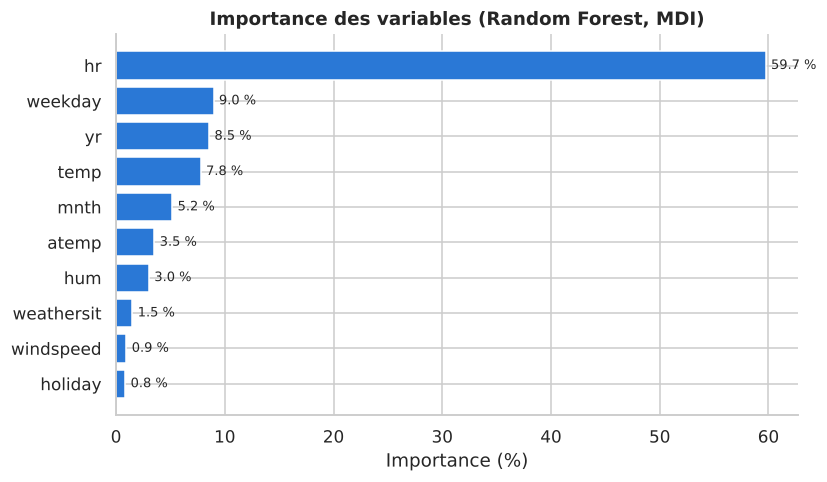

hr            59.7
weekday        9.0
yr             8.5
temp           7.8
mnth           5.2
atemp          3.5
hum            3.0
weathersit     1.5
windspeed      0.9
holiday        0.8


In [25]:
imp = pd.Series(prevision["RF"].feature_importances_, index=VARIABLES).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.index, imp.values * 100, color=BLEU)
for i, v in enumerate(imp.values * 100):
    ax.text(v + 0.5, i, f"{v:.1f} %", va="center", fontsize=8.5)
ax.set(title="Importance des variables (Random Forest, MDI)", xlabel="Importance (%)")
sauver(fig, "fig9_importance")
plt.show()
print((imp.sort_values(ascending=False) * 100).round(1).to_string())

**Finding (Constats chiffrés)**
* L'heure **`hr` représente 59,7 %** de l'importance totale, loin devant `weekday` (9,0 %), `yr` (8,5 %) et `temp` (7,8 %).

**Insights (Interprétation et lien avec l'article)**
* Ce résultat est cohérent avec l'exploration de l'Étape 1 : c'est le moment de la journée qui décide d'abord de la demande. La progression d'une année sur l'autre (`yr`) traduit la croissance du service entre 2011 et 2012.

## 5.3 Demande réelle contre demande prévue (Fig. 6 à 9 de l'article)

**Pourquoi ?** Les figures 6 à 9 de l'article superposent la demande réelle et la prévision de chaque modèle. On fait de même pour nos 6 méthodes, sur les 150 premières heures du test, rangées dans l'ordre chronologique.

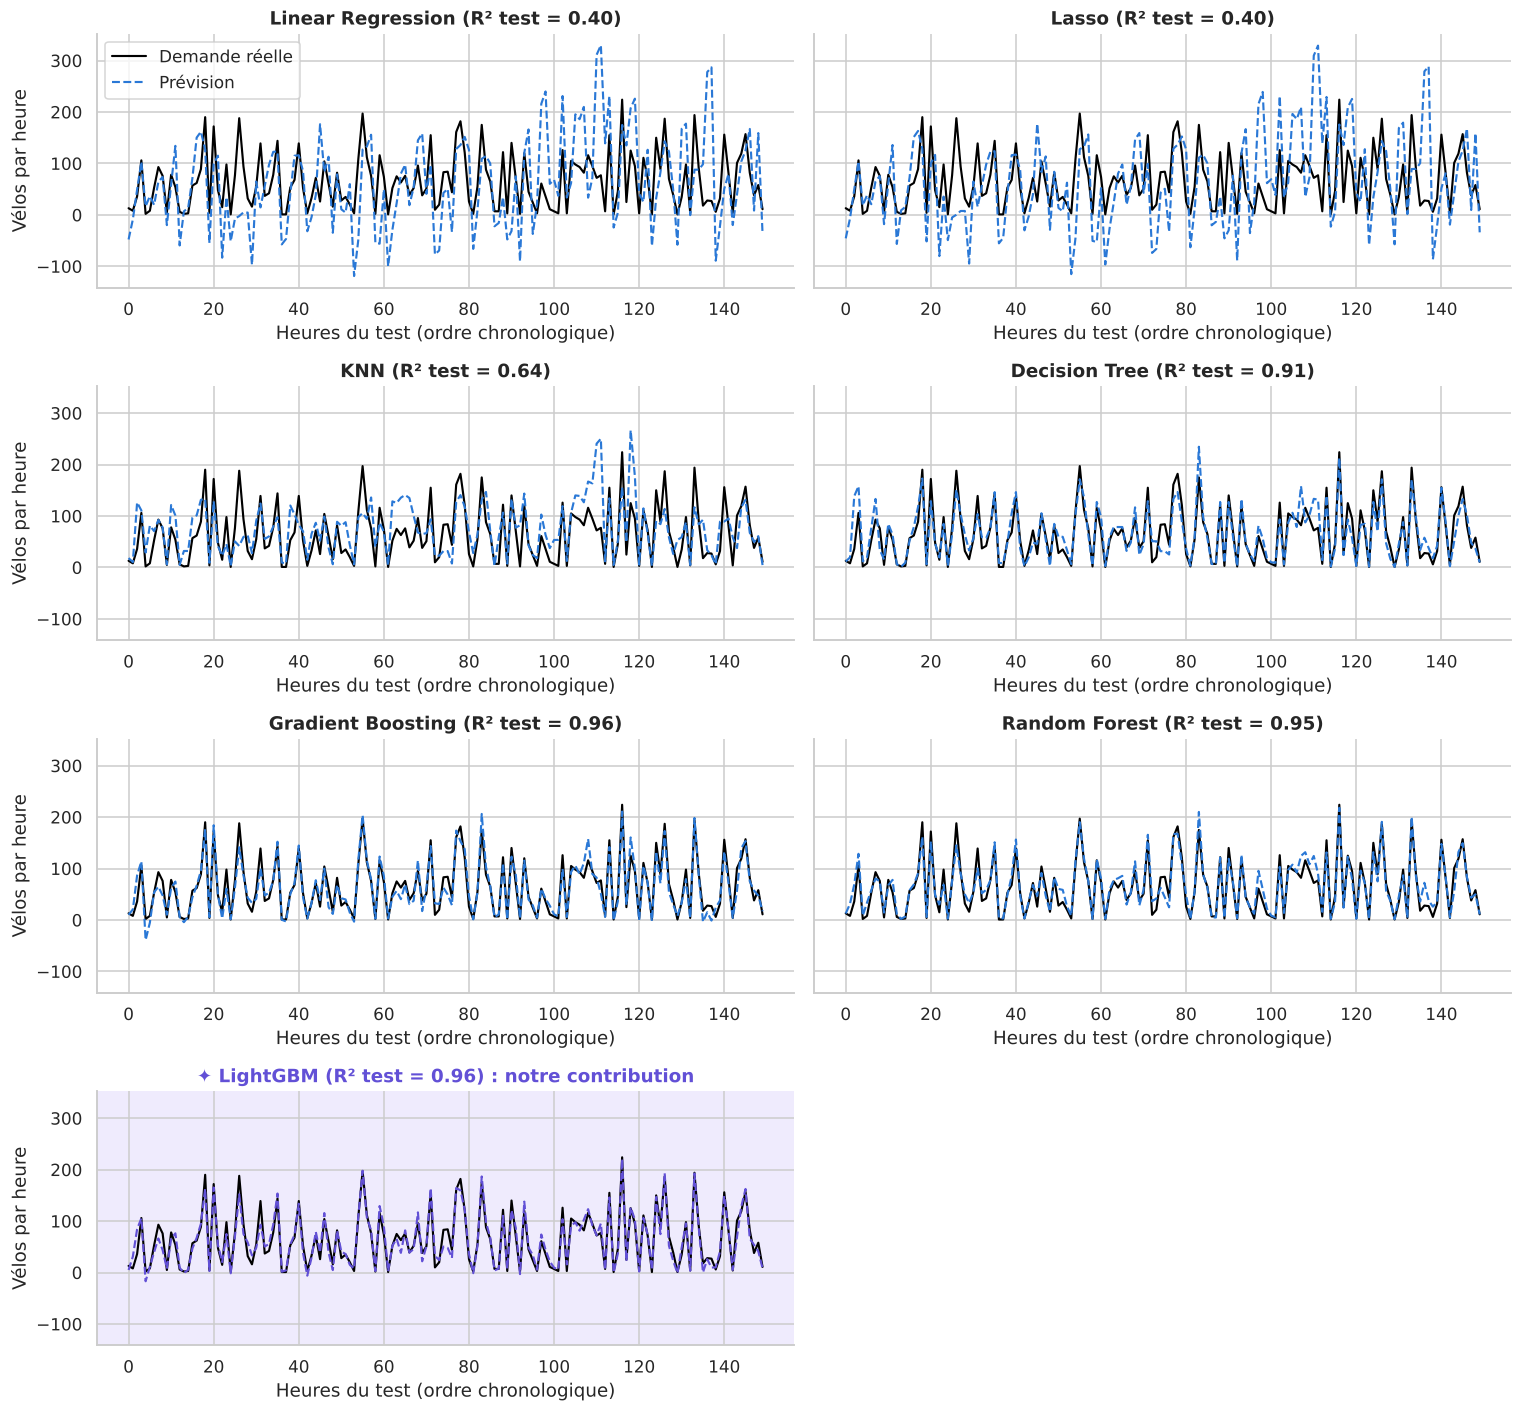

In [26]:
ordre_t = np.argsort(df.loc[X_test.index, "datetime"].values)   # heures du test dans l'ordre chronologique
fen = ordre_t[:150]
fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharey=True)
for ax, (m, nom) in zip(axes.ravel(), NOMS.items()):
    ax.plot(yte.values[fen], color="black", lw=1.4, label="Demande réelle")
    ax.plot(d_hat[m][fen], color=BLEU, lw=1.4, ls="--", label="Prévision")
    ax.set(title=f"{nom} (R² test = {r2_score(yte, d_hat[m]):.2f})", xlabel="Heures du test (ordre chronologique)")
for ligne in axes:
    ligne[0].set_ylabel("Vélos par heure")
ax_lgbm = axes.ravel()[list(NOMS).index("LGBM")]                                    # ✦ CONTRIBUTION
ax_lgbm.set_facecolor(VIOLET_CLAIR)
ax_lgbm.lines[1].set_color(VIOLET)
ax_lgbm.set_title("✦ " + ax_lgbm.get_title() + " : notre contribution", color=VIOLET)
axes.ravel()[-1].axis("off")
axes[0, 0].legend()
fig.tight_layout()
sauver(fig, "fig10_reel_vs_prevu")
plt.show()

**Finding (Constats chiffrés)**
* Les prévisions du Gradient Boosting et de la Random Forest suivent presque parfaitement la demande réelle, y compris les pics. Le Decision Tree suit bien la forme, avec des marches dues à ses feuilles.
* Le KNN suit la tendance mais rate une partie des pics.
* Les modèles linéaires lissent les pics et prévoient parfois une **demande négative** (parfois en dessous de -100 vélos), ce qui n'a pas de sens.
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> Le graphique sur fond violet montre que la prévision de LightGBM colle à la demande réelle comme celle du Gradient Boosting (R² = 0,96).

**Insights (Interprétation et lien avec l'article)**
* On retrouve visuellement les figures 6 à 9 de l'article : les méthodes à base d'arbres capturent la forme réelle de la demande, et les modèles linéaires n'en donnent qu'une tendance moyenne.

## 5.4 Tableau 9 : coût de stock sur 10 sous-périodes

**Pourquoi ?** Le Tableau 9 de l'article découpe la période d'évaluation en **10 sous-périodes** et compare le coût total de chaque stratégie dans chacune. Une moyenne peut cacher des périodes où la méthode perd ; ce découpage montre si le gain du FBNV est régulier. On range les 1 361 heures de test par ordre chronologique et on les coupe en 10 blocs de 136 ou 137 heures.

$$\text{Coût total}_p = \sum_{i \in p} \big[\,10\,(d_i - q_i)^+ + 4\,(q_i - d_i)^+\,\big]$$

In [27]:
periodes = np.array_split(ordre_t, 10)
colonnes = {}
for m in prevision:                                   # LR, LR+FB, LA, LA+FB, ... RF, RF+FB
    colonnes[m] = q_two[m]
    colonnes[m + "+FB"] = q_one[m]
tab9 = pd.DataFrame([{"Période": k, **{nom: cout(yte.values[idx], q[idx]) * len(idx) for nom, q in colonnes.items()}}
                     for k, idx in enumerate(periodes, 1)])
total = tab9.drop(columns="Période").sum()
moyenne = pd.Series({nom: cout(yte, q) for nom, q in colonnes.items()})
tab9 = pd.concat([tab9, pd.DataFrame([{"Période": "Total", **total}, {"Période": "Moyenne par heure", **moyenne}])],
                 ignore_index=True)
tableau(tab9, "Tableau 9 : Coût de stock total par sous-période (Two-Step contre One-Step FBNV)",
        {c: "{:,.0f}" for c in colonnes})
print("Le coût « Moyenne par heure » est le coût total divisé par 1 361 heures.")

for m in prevision:
    gagne = (tab9[f"{m}+FB"].values[:10] < tab9[m].values[:10]).sum()
    print(f"{m} : FBNV moins cher sur {gagne} périodes sur 10 ; baisse du coût total = {1 - total[m + '+FB'] / total[m]:.2%}")

Période,LR,LR+FB,LA,LA+FB,KNN,KNN+FB,DT,DT+FB,GB,GB+FB,RF,RF+FB,LGBM,LGBM+FB
1,"51,010","47,070","51,317","48,227","43,574","28,248","19,917","12,588","12,507","10,001","15,574","10,058","12,423","8,594"
2,"64,945","61,121","65,257","62,238","56,793","49,509","29,702","24,221","17,995","18,641","22,004","18,303","19,042","16,897"
3,"80,834","73,361","80,902","75,962","53,812","49,403","25,732","20,286","18,359","15,123","19,905","17,804","18,313","13,925"
4,"84,255","78,765","84,477","83,893","56,941","52,794","29,217","25,050","20,862","20,187","22,894","23,718","21,695","20,697"
5,"76,259","71,236","76,260","72,219","52,951","47,763","23,653","19,053","16,338","13,120","16,938","14,601","15,491","13,170"
6,"84,543","74,543","84,637","70,681","66,920","59,553","29,205","23,605","18,989","14,689","23,217","19,225","17,830","15,334"
7,"145,198","147,722","145,310","158,891","99,928","101,940","34,161","32,372","28,477","26,633","28,638","24,257","24,444","24,145"
8,"124,678","118,334","124,717","120,121","82,813","84,083","31,833","31,556","25,159","23,392","24,860","25,881","24,804","22,096"
9,"152,259","153,737","152,444","167,447","104,690","100,532","47,271","40,412","30,696","29,305","31,626","31,293","29,493","27,437"
10,"113,270","108,068","113,267","114,239","88,375","82,639","31,832","28,379","20,779","22,764","25,081","24,705","20,983","20,424"


Le coût « Moyenne par heure » est le coût total divisé par 1 361 heures.
LR : FBNV moins cher sur 8 périodes sur 10 ; baisse du coût total = 4.43%
LA : FBNV moins cher sur 7 périodes sur 10 ; baisse du coût total = 0.48%
KNN : FBNV moins cher sur 8 périodes sur 10 ; baisse du coût total = 7.12%
DT : FBNV moins cher sur 10 périodes sur 10 ; baisse du coût total = 14.88%
GB : FBNV moins cher sur 8 périodes sur 10 ; baisse du coût total = 7.76%
RF : FBNV moins cher sur 8 périodes sur 10 ; baisse du coût total = 9.05%
LGBM : FBNV moins cher sur 10 périodes sur 10 ; baisse du coût total = 10.66%


**Finding (Constats chiffrés)**
* Sur le coût total des 1 361 heures, le FBNV est moins cher pour les **6 méthodes** : -4,43 % (LR), -0,48 % (LA), -7,12 % (KNN), **-14,88 % (DT)**, -7,76 % (GB) et -9,05 % (RF).
* Période par période, le FBNV gagne **10 périodes sur 10 avec le Decision Tree**, 8 sur 10 avec LR, KNN, GB et RF, et 7 sur 10 avec le Lasso.
* Le coût total le plus bas est celui du **GB+FB (193 855)**.
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> **LGBM+FB** gagne **10 sous-périodes sur 10** contre LightGBM Two-Step (−10,66 % sur le total), comme dans l'article. Son coût total est le plus bas du tableau : **182 717**.

**Insights (Interprétation et lien avec l'article)**
* Dans l'article, le FBNV gagne les 10 périodes. On retrouve ce résultat avec le Decision Tree. Avec les autres méthodes, le FBNV gagne la grande majorité des périodes, avec un gain net sur le total. La conclusion est la même : la méthode One-Step réduit le coût de stock de façon régulière, et pas seulement en moyenne.
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> Avec LightGBM, on retrouve exactement le résultat de l'article : le FBNV est moins cher dans toutes les sous-périodes.

## 5.5 Décision de commande $q^*$ heure par heure

**Pourquoi ?** On regarde concrètement ce que commandent les deux stratégies avec le Gradient Boosting, sur 100 heures consécutives du test. La zone colorée est le **stock de sécurité** (l'écart entre la commande et la prévision moyenne) : fixe pour le Two-Step, variable selon l'heure pour le FBNV. Le tableau ajoute la colonne <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ LGBM+FB</span>.

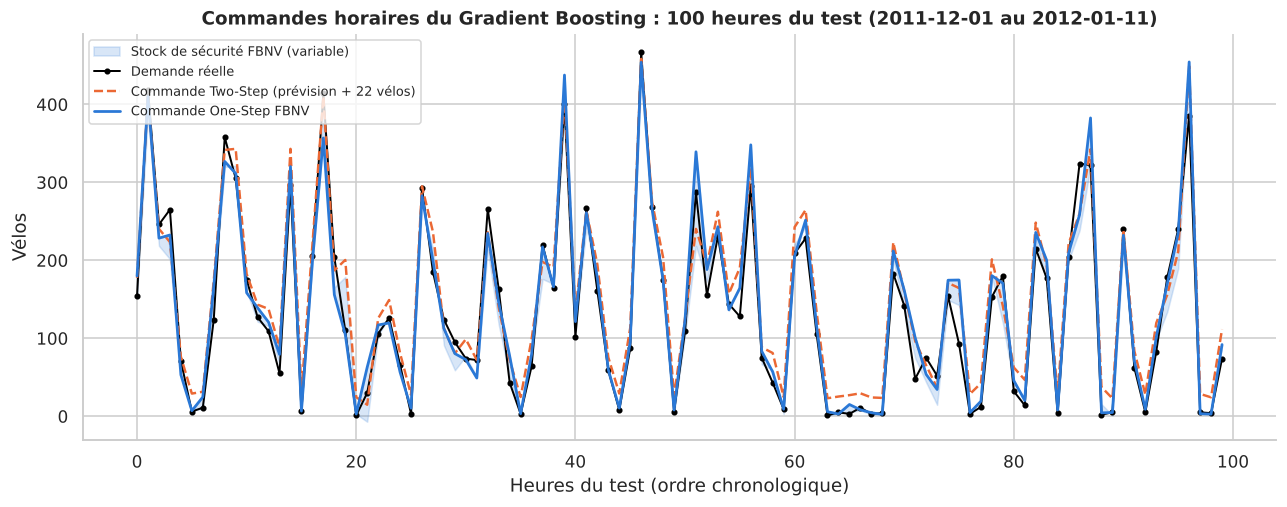

Tranche horaire,Heures,Marge Two-Step (vélos),Marge FBNV moyenne (vélos),Coût Two-Step,Coût FBNV,✦ Coût LGBM+FB
Nuit (0h-6h),403,21.81,4.44,94.50,46.66,42.52
"Pointe (7h-9h, 17h-19h)",333,21.81,24.41,217.63,234.66,220.56
Reste de la journée,625,21.81,14.97,159.37,155.06,147.42


In [28]:
dates_te = df.loc[X_test.index, "datetime"]
idx = ordre_t[600:700]                                   # 100 heures consécutives du test (ordre chronologique)
x = np.arange(len(idx))

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.fill_between(x, d_hat["GB"][idx], q_one["GB"][idx], color=BLEU, alpha=0.18, label="Stock de sécurité FBNV (variable)")
ax.plot(x, yte.values[idx], color="black", marker="o", ms=3, lw=1.3, label="Demande réelle")
ax.plot(x, q_two["GB"][idx], color=ORANGE, ls="--", lw=1.6, label=f"Commande Two-Step (prévision + {Z * sigma['GB']:.0f} vélos)")
ax.plot(x, q_one["GB"][idx], color=BLEU, lw=1.8, label="Commande One-Step FBNV")
ax.set(title=f"Commandes horaires du Gradient Boosting : 100 heures du test "
             f"({dates_te.values[idx[0]].astype('datetime64[D]')} au {dates_te.values[idx[-1]].astype('datetime64[D]')})",
       xlabel="Heures du test (ordre chronologique)", ylabel="Vélos")
ax.legend(loc="upper left", fontsize=8.5)
sauver(fig, "fig11_decision_q")
plt.show()

# Coût moyen par tranche horaire : la nuit, la marge fixe est trop grande ; aux heures de pointe, elle est trop petite
heure = X_test["hr"].values
tranches = {"Nuit (0h-6h)": heure <= 6, "Pointe (7h-9h, 17h-19h)": np.isin(heure, [7, 8, 9, 17, 18, 19]),
            "Reste de la journée": ~np.isin(heure, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 17, 18, 19])}
tab_h = pd.DataFrame([{"Tranche horaire": nom, "Heures": msk.sum(),
                       "Marge Two-Step (vélos)": Z * sigma["GB"],
                       "Marge FBNV moyenne (vélos)": (q_one["GB"] - d_hat["GB"])[msk].mean(),
                       "Coût Two-Step": cout(yte.values[msk], q_two["GB"][msk]),
                       "Coût FBNV": cout(yte.values[msk], q_one["GB"][msk]),
                       "✦ Coût LGBM+FB": cout(yte.values[msk], q_one["LGBM"][msk])}            # ✦ CONTRIBUTION
                      for nom, msk in tranches.items()])
tableau(tab_h, "Tableau 5.5 : Marge et coût moyen par tranche horaire (Gradient Boosting)")

**Finding (Constats chiffrés)**
* Le Two-Step ajoute toujours la même marge de **21,8 vélos**. La marge du FBNV va en moyenne de **4,4 vélos la nuit** à **24,4 vélos aux heures de pointe**.
* **La nuit**, le FBNV divise le coût par deux (**94,50 à 46,66**). **Aux heures de pointe**, il est un peu plus cher (**217,63 contre 234,66**). Sur le reste de la journée, les deux sont proches.
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> **LGBM+FB** est moins cher que GB+FB dans les 3 tranches : 42,52 la nuit (contre 46,66), **220,56 aux heures de pointe** (contre 234,66) et 147,42 le reste de la journée (contre 155,06).

**Insights (Interprétation et lien avec l'article)**
* C'est exactement le mécanisme décrit par l'article : le FBNV adapte le stock de sécurité à l'incertitude de chaque heure. Il évite surtout de payer des vélos inutiles la nuit.
* Aux heures de pointe, notre GB+FB commande encore un peu trop peu. C'est une piste d'amélioration à mentionner à l'oral.
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> LightGBM réduit en partie notre point faible aux heures de pointe (−6 % par rapport à GB+FB), grâce à sa croissance feuille par feuille, qui se concentre sur les cas difficiles. Le Two-Step reste un peu moins cher à ces heures-là (217,63) : c'est la piste d'amélioration suivante.

## 5.6 Export Excel pour le rendu Moodle

**Pourquoi ?** Le cahier des charges demande de déposer la base de données au format Excel. Le fichier `donnees_propres_GP27_FBNV.xlsx` contient les données nettoyées, les décisions de commande sur le test, les deux tableaux de l'article et un onglet <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution_LightGBM</span>.

In [29]:
decisions = pd.DataFrame({"datetime": dates_te.values, "demande_reelle": yte.values})
for m in prevision:
    decisions[f"prevision_{m}"] = d_hat[m].round(1)
    decisions[f"q_two_step_{m}"] = q_two[m].round(1)
    decisions[f"q_fbnv_{m}"] = q_one[m].round(1)
decisions = decisions.sort_values("datetime")

lisez_moi = pd.DataFrame({"Onglet": ["Donnees_propres", "Decisions_test", "Tableau_8", "Tableau_9", "Contribution_LightGBM"],
                          "Contenu": ["10 886 heures après nettoyage (sans casual ni registered, variables temporelles ajoutées)",
                                      "Demande réelle, prévision et commandes Two-Step / FBNV pour chaque heure du test",
                                      "Précision des prévisions sur le test (RMSE, MAE, MSE, R²)",
                                      "Coût de stock par sous-période (b = 10, h = 4)",
                                      "✦ Notre contribution : LGBM+FB contre GB+FB (colonnes *_LGBM dans Decisions_test)"]})

with pd.ExcelWriter("donnees_propres_GP27_FBNV.xlsx") as xls:
    lisez_moi.to_excel(xls, sheet_name="Lisez-moi", index=False)
    df[["datetime"] + FEATURES + [TARGET]].to_excel(xls, sheet_name="Donnees_propres", index=False)
    decisions.to_excel(xls, sheet_name="Decisions_test", index=False)
    tab8.to_excel(xls, sheet_name="Tableau_8", index=False)
    tab9.to_excel(xls, sheet_name="Tableau_9", index=False)
    bilan.to_excel(xls, sheet_name="Contribution_LightGBM", index=False)                     # ✦ CONTRIBUTION
print("Fichier écrit : donnees_propres_GP27_FBNV.xlsx")
print({"Donnees_propres": len(df), "Decisions_test": len(decisions)})

Fichier écrit : donnees_propres_GP27_FBNV.xlsx
{'Donnees_propres': 10886, 'Decisions_test': 1361}


**Finding (Constats chiffrés)**
* Le fichier Excel contient 5 onglets : `Lisez-moi`, `Donnees_propres` (10 886 lignes), `Decisions_test` (1 361 lignes), `Tableau_8` et `Tableau_9`.
* <span style="background:#efebfd; color:#3b2a9e; font-weight:bold; padding:1px 8px; border-radius:4px;">✦ Contribution</span> Un 6e onglet, `Contribution_LightGBM`, contient le Tableau 4.5. Les colonnes `*_LGBM` de `Decisions_test` donnent les commandes LightGBM heure par heure.

**Insights (Interprétation et lien avec l'article)**
* Ce fichier répond au rendu demandé sur Moodle (base de données Excel). Il permet aussi de refaire les calculs de coût à la main dans Excel pour les vérifier.

# Conclusion

**Ce qu'on a reproduit.** On a appliqué toute la démarche de Jing Shi (2022) aux données de vélos en libre-service :
1. préparation des données et suppression de la fuite (`casual`, `registered`) ;
2. sélection des variables par Lasso, qui retient 10 variables sur 12 ;
3. comparaison de **10 méthodes de prévision**, où les méthodes à base d'arbres (R² de 0,89 à 0,96) battent nettement les modèles linéaires (R² ≈ 0,40) ;
4. comparaison des deux stratégies de stock sur **6 méthodes**, avec $b = 10$, $h = 4$ et $\alpha^* = 0{,}7143$.

**Résultat principal.** La méthode **One-Step FBNV** coûte moins cher que la méthode Two-Step pour les 6 méthodes testées, avec des baisses de -0,48 % à -14,88 %. Le meilleur résultat est celui du **Gradient Boosting quantile (GB+FB)** : **142,44 par heure** contre 154,42 en Two-Step, soit **-7,76 %**. Le gain vient d'un stock de sécurité qui s'adapte à chaque heure : petit la nuit, plus grand aux heures de pointe.

<div style="border-left:6px solid #6250d6; background:#f4f1fe; padding:12px 18px; border-radius:8px; margin:8px 0;">
<p style="margin:0 0 6px 0; color:#6250d6; font-weight:bold;">✦ NOTRE CONTRIBUTION : LightGBM</p>
<p style="margin:0;">En ajoutant LightGBM, une méthode de 2017 absente de l'article, et en l'entraînant directement sur le coût de stock (LGBM+FB), on obtient le <b>meilleur résultat du projet : 134,25 par heure</b>. C'est <b>5,75 % de moins</b> que le meilleur modèle d'avant (GB+FB) et <b>13,06 % de moins</b> que la méthode classique Two-Step avec Gradient Boosting. LGBM+FB gagne aussi <b>10 sous-périodes sur 10</b> dans le Tableau 9, comme dans l'article. Prochaine étape envisagée : XGBoost, pour vérifier que le gain ne dépend pas d'une seule méthode.</p>
</div>

**Différences avec l'article.** Le FBNV gagne les 10 sous-périodes avec le Decision Tree, mais 7 ou 8 sur 10 avec les autres méthodes. Le gain est faible avec le Lasso (-0,48 %), et le FBNV est légèrement plus cher aux heures de pointe. Les données et le contexte sont différents (vélos heure par heure contre voitures mois par mois), mais la conclusion de l'article est confirmée.